# Mobile App Screens and Text Descriptions Cross Modal Retrival
---
## Varun Manjunath
## Student ID: a1947566
## Group 21
---

## Setup and install libraries

In [1]:
# Install libraries
%pip install -q "datasets>=4.0,<5" "transformers>=5.18,<5.23" "huggingface-hub>=1.32,<2" "pyarrow>=19,<24" "scikit-learn>=1.3" "seaborn>=0.13"

In [2]:
import os, io, re, json, time, math, random, copy, platform, textwrap
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset
from PIL import Image, ImageOps, ImageStat
from IPython.display import display
from tqdm.auto import tqdm
from scipy.fft import dctn
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from datasets import load_dataset
from huggingface_hub import HfApi, hf_hub_url
from torchvision import models, transforms
from transformers import AutoTokenizer, AutoModel

DATASET_ID = "bevaya/RICO-Screen2Words"
SEED = 42
N_SCREENS = 4000
BUFFER_SIZE = 2500
IMAGE_SIZE = 224
MAX_TEXT_TOKENS = 16
FEATURE_DIM = 128
IMG_BATCH = 48
TEXT_BATCH = 64
CONTRASTIVE_EPOCHS = 20
EARLY_EPOCHS = 16
BATCH_SIZE = 96
PATIENCE = 5
TRAIN_SEEDS = [42, 123, 456]
RETRIEVAL_TOP_K = 30
MANUAL_EXCLUDE_SCREEN_IDS = []

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE != "cuda":
    print("WARNING: a T4 GPU is strongly recommended; CPU inference can be slow.")

ROOT = Path("/content/rico_group21_proposal_final") if Path("/content").exists() else Path("rico_group21_proposal_final")
CACHE = ROOT / f"cache_n{N_SCREENS}_s{SEED}_tok{MAX_TEXT_TOKENS}"
IMAGE_DIR = CACHE / "images_private"
OUT = ROOT / "submission_outputs"
TAB = OUT / "tables"
for folder in (IMAGE_DIR, TAB): folder.mkdir(parents=True, exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed(SEED)

COLORS = {"Random":"#8896A6", "Ridge":"#EA6D6D", "Early fusion":"#8365B8",
          "Contrastive":"#008B8B", "Hybrid reranker":"#D89B42"}
sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update({"figure.dpi":115, "axes.spines.top":False,
                     "axes.spines.right":False, "axes.titleweight":"bold"})

def show_plot(fig):
    """Display a plot here in Colab, without writing a PNG/PDF file."""
    plt.show()
    plt.close(fig)

def seconds_now():
    if DEVICE == "cuda": torch.cuda.synchronize()
    return time.perf_counter()

print("Python:", platform.python_version(), "| PyTorch:", torch.__version__)
print("Compute device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU (slower)")
print("Charts will display in Colab only: no plot files will be saved.")
print("Primary metrics: strict ownership; relaxed metrics are shown separately.")

Python: 3.13.16 | PyTorch: 2.14.1+cu130
Compute device: Tesla T4
Charts will display in Colab only: no plot files will be saved.
Primary metrics: strict ownership; relaxed metrics are shown separately.


## Dataset provenance


In [3]:
from huggingface_hub import HfApi

hub = HfApi()
info = hub.dataset_info(DATASET_ID)
licence = getattr(info.card_data, "license", "not specified") if info.card_data else "not specified"
print("Dataset:", DATASET_ID)
print("Licence listed on the dataset card:", licence)
print("Dataset webpage: https://huggingface.co/datasets/" + DATASET_ID)
print("This is a reproducible subset of the ORIGINAL TRAIN partition.")

Dataset: bevaya/RICO-Screen2Words
Licence listed on the dataset card: cc-by-4.0
Dataset webpage: https://huggingface.co/datasets/bevaya/RICO-Screen2Words
This is a reproducible subset of the ORIGINAL TRAIN partition.


## Load the dataset

In [4]:
def clean_text(value):
    """Turn repeated whitespace into one space."""
    return re.sub(r"\s+", " ", str(value)).strip()

def canonical(value):
    """A consistent comparison key for captions shared by several screens."""
    return re.sub(r"[^a-z0-9 ]+", " ", clean_text(value).lower()).strip()

# We flag identifiers in text
PERSONAL_TEXT_RE = re.compile(r"[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}|(?:\+?\d[\d ()-]{8,}\d)")
SENSITIVE_SCREEN_RE = re.compile(r"\b(?:password|login|log in|sign in|payment|credit card|bank|account number|address)\b", re.I)

def clean_captions(values):
    if isinstance(values, str):
        values = [values]
    elif values is None:
        values = []
    else:
        values = list(values)
    answer, seen = [], set()
    for value in values:
        text = clean_text(value)
        key = canonical(text)
        if not key or key in seen or PERSONAL_TEXT_RE.search(text):
            continue
        answer.append(text)
        seen.add(key)
    return answer

def open_screenshot(image_item):
    """Parquet image cells can be PIL images or {bytes, path} dictionaries."""
    if isinstance(image_item, Image.Image):
        return ImageOps.exif_transpose(image_item).convert("RGB")
    if isinstance(image_item, dict):
        if image_item.get("bytes") is not None:
            return ImageOps.exif_transpose(Image.open(io.BytesIO(image_item["bytes"]))).convert("RGB")
        if image_item.get("path"):
            return ImageOps.exif_transpose(Image.open(image_item["path"])).convert("RGB")
    raise ValueError("Unsupported or empty image format")

# Find actual Parquet files in this dataset
repo_files = HfApi().list_repo_files(repo_id=DATASET_ID, repo_type="dataset")
train_parquet = sorted(name for name in repo_files
                       if name.startswith("data/train-") and name.endswith(".parquet"))
assert train_parquet, "No train Parquet files were found: check the Hugging Face dataset URL."
direct_urls = [hf_hub_url(repo_id=DATASET_ID, filename=name, repo_type="dataset")
               for name in train_parquet]
print("Direct Parquet files:", len(direct_urls))
print("First URL:", direct_urls[0])

selected = ["screenId", "captions", "app_package_name", "play_store_name", "category",
            "average_rating", "number_of_ratings", "number_of_downloads", "image"]
stream = load_dataset("parquet", data_files={"train":direct_urls},
                      split="train", streaming=True)
stream = stream.select_columns(selected).shuffle(seed=SEED, buffer_size=BUFFER_SIZE)

meta_path = CACHE / "screens.csv"
if meta_path.exists():
    screens = pd.read_csv(meta_path).fillna({"category":"Unknown"})
    screens["captions"] = screens["captions_json"].apply(json.loads)
    print("Reusing cached screenshot sample. Delete this cache if you change cleaning rules.")
else:
    rows, seen_ids = [], set()
    rejected_images = rejected_text = excluded = 0
    raw_screens_seen = 0
    raw_captions_seen = 0
    captions_discarded = 0
    reported_missing_app = 0
    iterator = stream.take(N_SCREENS + 900)
    for item in tqdm(iterator, desc="Screens from direct Hugging Face URLs"):
        raw_screens_seen += 1
        sid = int(item["screenId"])
        if sid in seen_ids:
            continue
        seen_ids.add(sid)
        if sid in MANUAL_EXCLUDE_SCREEN_IDS:
            excluded += 1
            continue
        raw_values = item.get("captions") or []
        if isinstance(raw_values, str):
            raw_values = [raw_values]
        raw_captions_seen += len(raw_values)
        captions = clean_captions(raw_values)
        captions_discarded += len(raw_values) - len(captions)
        if not captions:
            rejected_text += 1
            continue
        try:
            original = open_screenshot(item["image"])
            width, height = original.size
            if width < 50 or height < 50:
                raise ValueError("Unusually small screenshot")
            image = ImageOps.pad(original, (IMAGE_SIZE, IMAGE_SIZE),
                                 method=Image.Resampling.LANCZOS,
                                 color=(245, 245, 245))
            image_path = IMAGE_DIR / f"{sid}.jpg"
            image.save(image_path, quality=90)
            grayscale = np.asarray(image.convert("L").resize((64, 64)), dtype=np.float32)
            brightness = float(grayscale.mean())
            contrast = float(grayscale.std())
            small_rgb = np.asarray(image.resize((64, 64)), dtype=np.uint8)
            colour_bins = int(len(np.unique((small_rgb // 32).reshape(-1,3), axis=0)))
        except Exception:
            rejected_images += 1
            continue
        raw_app = str(item.get("app_package_name") or "").strip()
        if not raw_app:
            reported_missing_app += 1
        rows.append({"screenId":sid,
                     "app":raw_app or f"unknown_{sid}",
                     "app_name":str(item.get("play_store_name") or "Unknown"),
                     "average_rating":item.get("average_rating"),
                     "downloads":str(item.get("number_of_downloads") or "Unknown"),
                     "number_of_ratings":str(item.get("number_of_ratings") or "Unknown"),
                     "captions_before":len(raw_values),"captions_after":len(captions),
                     "category":str(item.get("category") or "Unknown"),
                     "width":width,"height":height,"brightness":brightness,
                     "contrast":contrast,"colour_bins":colour_bins,
                     "captions":captions,"captions_json":json.dumps(captions),
                     "sensitive_keyword":int(any(SENSITIVE_SCREEN_RE.search(t) for t in captions)),
                     "image_path":str(image_path)})
        if len(rows) >= N_SCREENS:
            break
    screens = pd.DataFrame(rows)
    assert len(screens) >= 250, "Too few usable screens; check data access or N_SCREENS."
    screens.to_csv(meta_path, index=False)
    load_audit = {"raw_screens_checked":int(raw_screens_seen),
                  "raw_captions_checked":int(raw_captions_seen),
                  "removed_caption_entries":int(captions_discarded),
                  "screen_rows_without_valid_text":int(rejected_text),
                  "unreadable_or_too_small_screens":int(rejected_images),
                  "manual_screen_exclusions":int(excluded),
                  "retained_screens":int(len(screens))}
    (CACHE/"load_audit.json").write_text(json.dumps(load_audit, indent=2))
    print("Rejected text-only screens:",rejected_text,
          "| corrupt/too-small images:",rejected_images,
          "| manual ID exclusions:",excluded)

if MANUAL_EXCLUDE_SCREEN_IDS:
    screens = screens[~screens.screenId.isin(MANUAL_EXCLUDE_SCREEN_IDS)].copy()
screens = screens.reset_index(drop=True)
screens["screen_idx"] = np.arange(len(screens))
caption_rows = [{"screen_idx":int(row.screen_idx), "caption":text,"norm":canonical(text)}
                for row in screens.itertuples() for text in row.captions]
cap_table = pd.DataFrame(caption_rows)
assert screens.screenId.is_unique
assert len(cap_table) > 0 and cap_table.groupby("screen_idx").size().min() >= 1
assert all(Path(p).is_file() for p in screens.image_path), "Private image cache is missing."
print(f"Dataset subset: {len(screens):,} screens; {len(cap_table):,} descriptions; {screens.app.nunique():,} apps")
display(screens[["screenId","app_name","category","average_rating","downloads","width","height"]].head())
print("Available dataset columns:", selected)
print("Source contains screenshot images, text summaries and app metadata.")


Direct Parquet files: 8
First URL: https://huggingface.co/datasets/bevaya/RICO-Screen2Words/resolve/main/data/train-00000-of-00008.parquet


Screens from direct Hugging Face URLs: 0it [00:00, ?it/s]

Rejected text-only screens: 0 | corrupt/too-small images: 0 | manual ID exclusions: 0
Dataset subset: 4,000 screens; 19,810 descriptions; 1,487 apps


,screenId,app_name,category,average_rating,downloads,width,height
0,27828,Trulia Rent Apartments & Homes,House & Home,4.4,"5,000,000 - 10,000,000",1080,1920
1,35657,Winter Keyboard Themes,Lifestyle,4.1,"100,000 - 500,000",1080,1920
2,34532,Country Music RADIO,Music & Audio,4.2,"500,000 - 1,000,000",1080,1920
3,31933,"One Message 7 - Emoji, Flat",Communication,4.4,"100,000 - 500,000",1080,1920
4,31845,Weather Services,Weather,4.1,"1,000,000 - 5,000,000",1080,1920


Available dataset columns: ['screenId', 'captions', 'app_package_name', 'play_store_name', 'category', 'average_rating', 'number_of_ratings', 'number_of_downloads', 'image']
Source contains screenshot images, text summaries and app metadata.


## Data exploration

,Check,Value
0,Screens after cleaning,4000.00
1,Captions after cleaning,19810.00
2,Unique Android apps,1487.00
3,Median captions / screen,5.00
4,Captions shared across screens (%),20.25
5,Screens with login/payment words (%),10.95
6,Unknown categories,0.00
7,Repeated screen IDs,0.00
8,Almost blank screenshots (contrast < 3),0.00


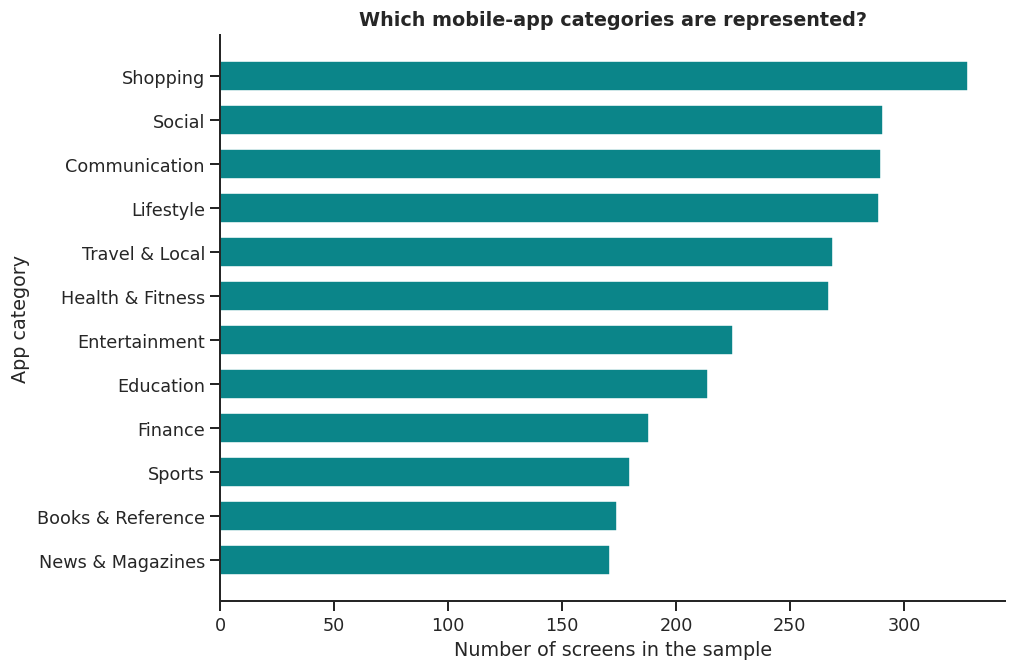

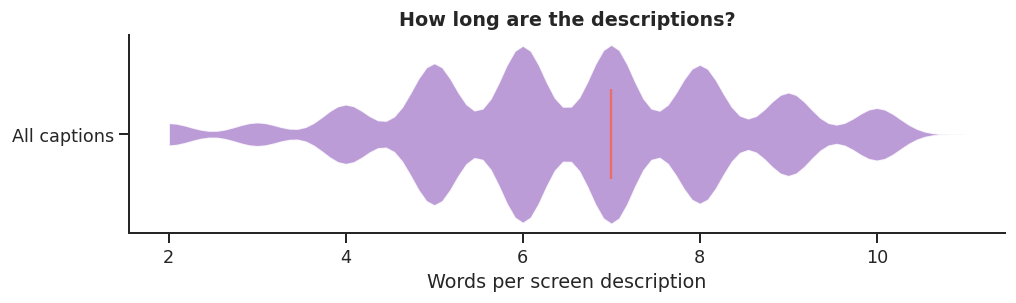

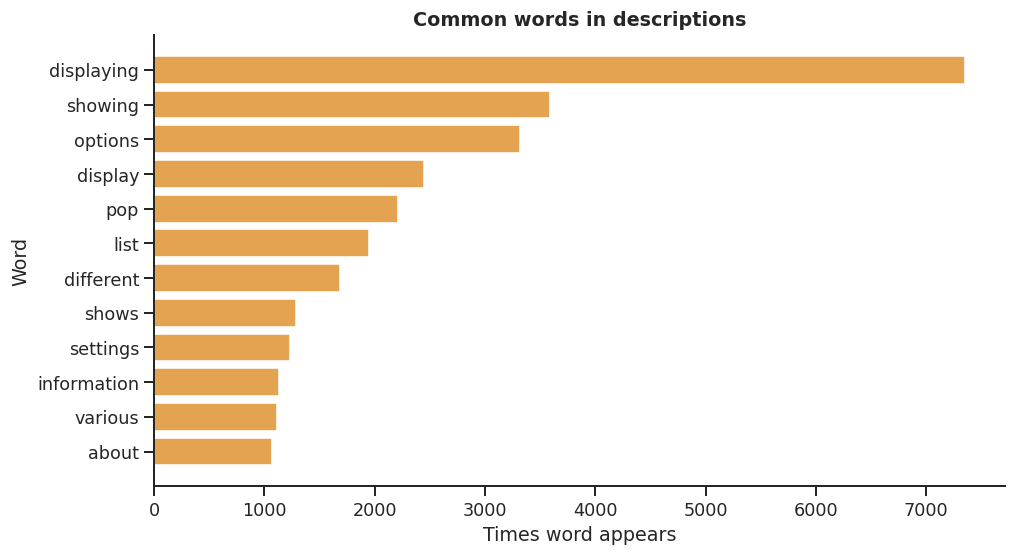

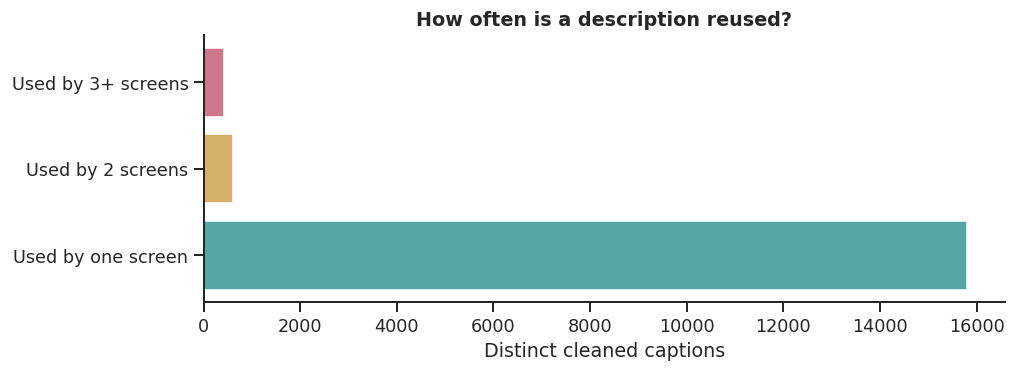

Most reused captions (sample only):


,Screens using these words
norm,
welcome page,128
sign in page,70
login page,59
settings page,58
sign up page,45
home page,36
page displaying different options,32
display image of options,32


In [5]:
#Every caption belongs tno exactly one screen
cap_table["words"] = cap_table["caption"].str.split().str.len()
cap_table["characters"] = cap_table["caption"].str.len()
caption_owners = cap_table.groupby("norm")["screen_idx"].nunique()
shared_keys = set(caption_owners[caption_owners > 1].index)
cap_table["shared_description"] = cap_table.norm.isin(shared_keys)

#Quality summary
quality = pd.DataFrame({
    "Check": ["Screens after cleaning", "Captions after cleaning", "Unique Android apps",
              "Median captions / screen", "Captions shared across screens (%)",
              "Screens with login/payment words (%)", "Unknown categories",
              "Repeated screen IDs", "Almost blank screenshots (contrast < 3)"],
    "Value": [len(screens),len(cap_table),screens.app.nunique(),
              int(screens.captions.map(len).median()),
              round(cap_table.shared_description.mean()*100,2),
              round(screens.sensitive_keyword.mean()*100,2),
              int(screens.category.eq("Unknown").sum()),
              int(screens.screenId.duplicated().sum()),
              int((screens.contrast < 3).sum())]
})
display(quality)
quality.to_csv(TAB/"data_quality_summary.csv",index=False)

#App category
categories = screens.category.value_counts().head(12).sort_values()
fig,ax=plt.subplots(figsize=(9,6))
ax.barh(categories.index,categories.values,color="#0B8589",height=.68)
ax.set(xlabel="Number of screens in the sample",ylabel="App category",
       title="Which mobile-app categories are represented?")
fig.tight_layout(); show_plot(fig)

# Caption lengths
fig,ax=plt.subplots(figsize=(9,2.8))
parts=ax.violinplot(cap_table.words,vert=False,showmedians=True,showextrema=False)
for part in parts["bodies"]:part.set_facecolor("#B18BD0");part.set_alpha(.85)
parts["cmedians"].set_color("#EA6D6D")
ax.set(xlabel="Words per screen description",yticks=[1],yticklabels=["All captions"],
       title="How long are the descriptions?")
fig.tight_layout(); show_plot(fig)

# Common words
stopwords={"the","a","an","to","and","of","for","with","in","on","is","are","this",
           "that","screen","page","app","application","it","can","there","has","be","by"}
words=Counter(word for phrase in cap_table.norm for word in phrase.split()
              if len(word)>2 and word not in stopwords)
common=pd.Series(dict(words.most_common(12))).sort_values()
fig,ax=plt.subplots(figsize=(9,5))
ax.barh(common.index,common.values,color="#E4A350")
ax.set(xlabel="Times word appears",ylabel="Word",title="Common words in descriptions")
fig.tight_layout();show_plot(fig)

fig,ax=plt.subplots(figsize=(9,3.4))
repeat_type=pd.Series({"Used by one screen":int((caption_owners==1).sum()),
                       "Used by 2 screens":int((caption_owners==2).sum()),
                       "Used by 3+ screens":int((caption_owners>=3).sum())})
ax.barh(repeat_type.index,repeat_type.values,color=["#56A6A5","#D6AF69","#CE778A"])
ax.set(xlabel="Distinct cleaned captions",ylabel="",title="How often is a description reused?")
fig.tight_layout(); show_plot(fig)

print("Most reused captions (sample only):")
display(caption_owners.sort_values(ascending=False).head(8).to_frame("Screens using these words"))
cap_table[["words","characters","shared_description"]].to_csv(
    TAB/"caption_quality.csv",index=False)

### App metadata completeness and coverage

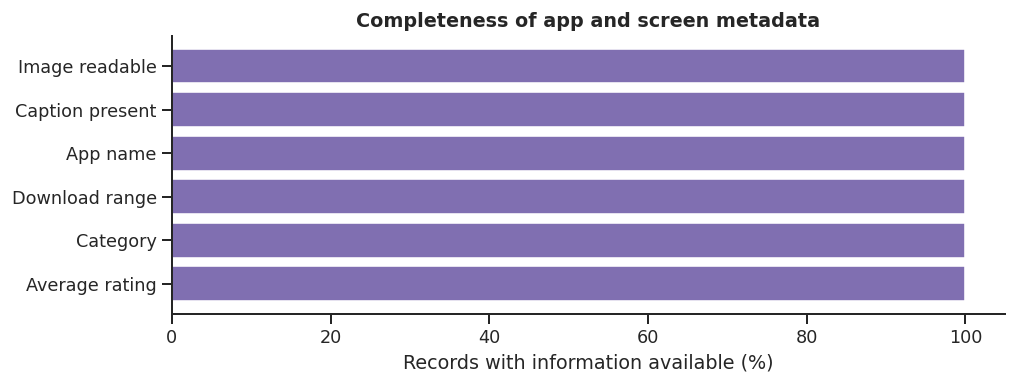

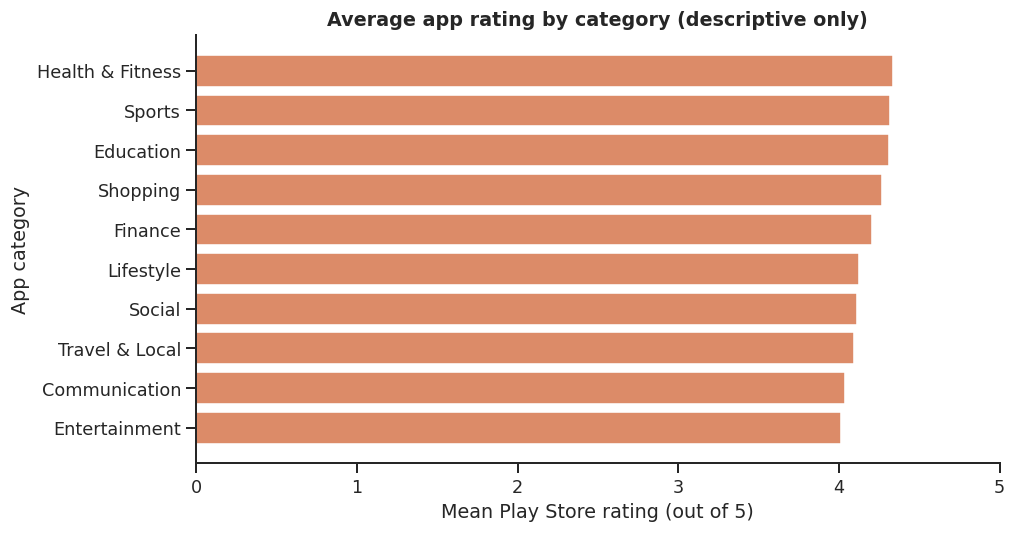

Ratings and categories are NOT fed into the retrieval models.


In [6]:
screens["average_rating"] = pd.to_numeric(screens["average_rating"],errors="coerce")
completeness = pd.Series({
    "Average rating":100*screens.average_rating.notna().mean(),
    "Category":100*screens.category.ne("Unknown").mean(),
    "Download range":100*screens.downloads.ne("Unknown").mean(),
    "App name":100*screens.app_name.ne("Unknown").mean(),
    "Caption present":100*screens.captions.map(bool).mean(),
    "Image readable":100*screens.image_path.map(lambda p: Path(p).exists()).mean(),
}).sort_values()
fig,ax=plt.subplots(figsize=(9,3.5))
ax.barh(completeness.index,completeness.values,color="#806FB1")
ax.set(xlim=(0,105),xlabel="Records with information available (%)",
       title="Completeness of app and screen metadata")
fig.tight_layout();show_plot(fig)

#Ratings
rated = screens.dropna(subset=["average_rating"])
if len(rated):
    cat_ratings = rated.groupby("category").agg(mean_rating=("average_rating","mean"),
                                                count=("screenId","size"))
    cat_ratings = cat_ratings[cat_ratings["count"]>=10].sort_values("count",ascending=False).head(10)
    cat_ratings = cat_ratings.sort_values("mean_rating")
    if len(cat_ratings):
        fig,ax=plt.subplots(figsize=(9,4.8))
        ax.barh(cat_ratings.index,cat_ratings.mean_rating,color="#DC8B68")
        ax.set(xlabel="Mean Play Store rating (out of 5)",ylabel="App category",
               xlim=(0,5),title="Average app rating by category (descriptive only)")
        fig.tight_layout();show_plot(fig)

meta_export = screens[["screenId","category","app","app_name","downloads","average_rating"]].copy()
meta_export.to_csv(TAB/"app_metadata_sample.csv",index=False)
print("Ratings and categories are NOT fed into the retrieval models.")

## Data exploration: screenshots and image quality

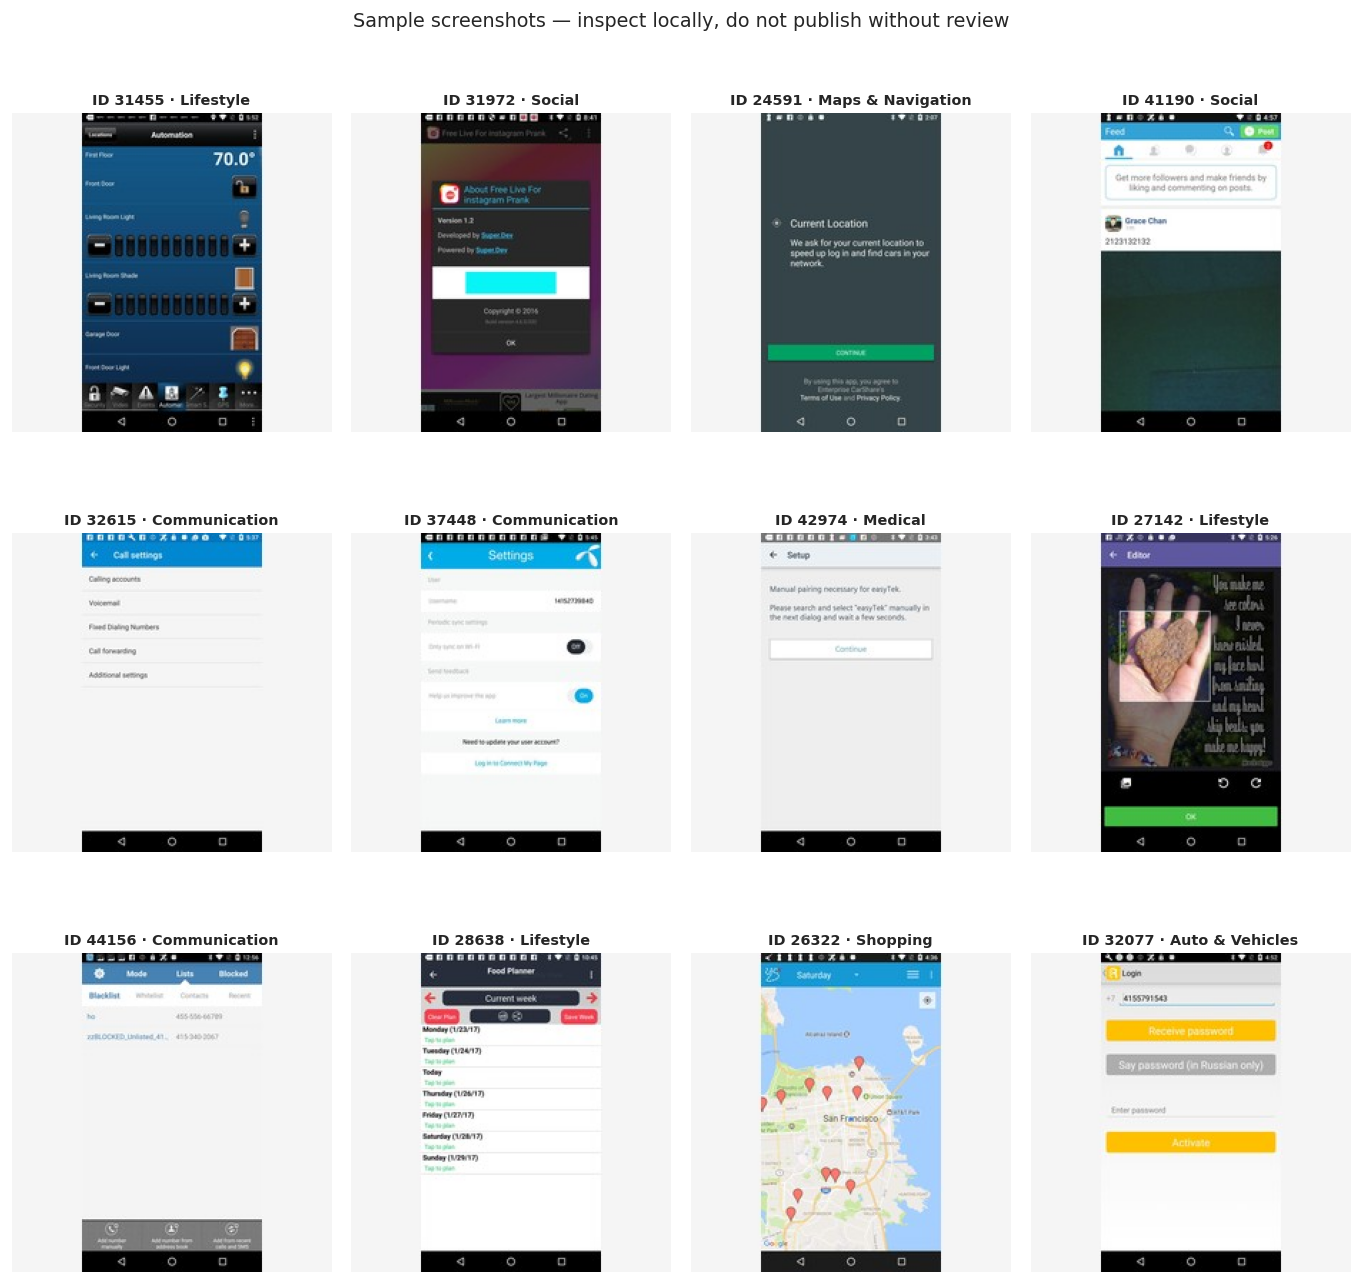

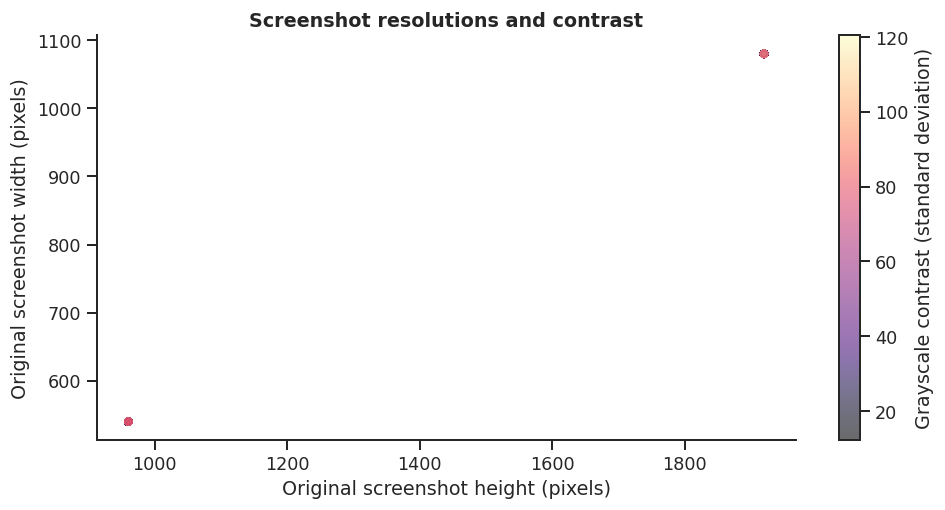

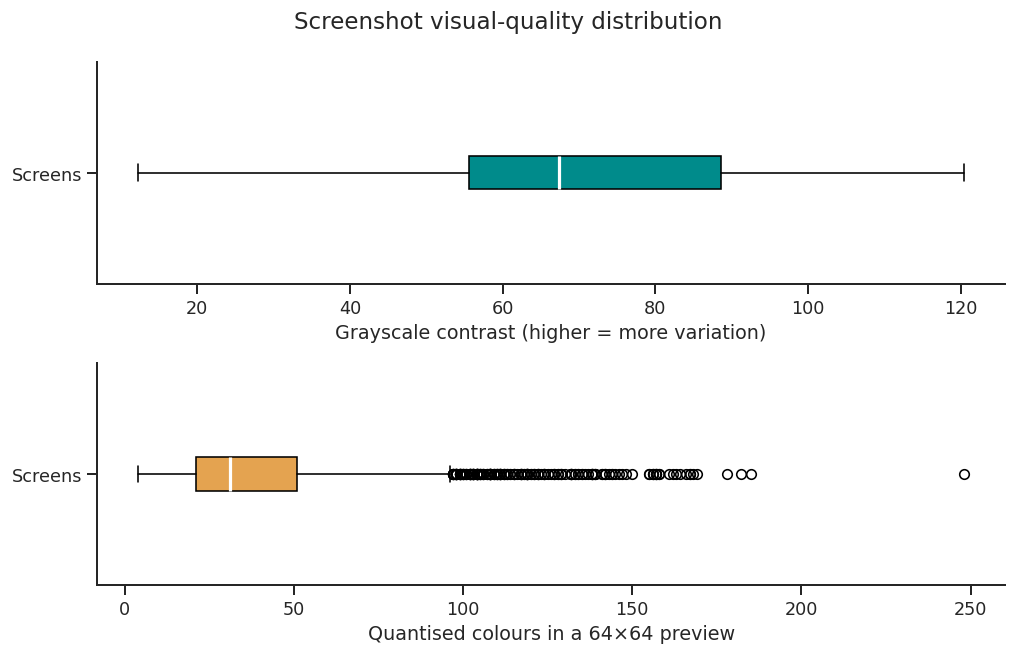

,Check,Value
0,Screens retained,4000.00
1,Different screen resolutions,2.00
2,Median height (px),1920.00
3,Median width (px),1080.00
4,Almost-blank screens (contrast < 3),0.00
5,Median quantised colours,31.00
6,Median grayscale contrast,67.42


In [7]:
# Screenshot preview
rng = np.random.default_rng(SEED + 7)
selected_preview = rng.choice(len(screens),size=min(12,len(screens)),replace=False)
fig,axes=plt.subplots(3,4,figsize=(12,12))
for ax,row_index in zip(axes.flat,selected_preview):
    record=screens.iloc[int(row_index)]
    with Image.open(record.image_path) as picture:
        ax.imshow(picture)
    ax.set_title(f"ID {record.screenId} · {record.category[:20]}",fontsize=9)
    ax.axis("off")
for ax in axes.flat[len(selected_preview):]:ax.axis("off")
fig.suptitle("Sample screenshots — inspect locally, do not publish without review",fontsize=12)
fig.tight_layout();plt.show();plt.close(fig)   # preview is deliberately NOT saved

# Width/height
fig,ax=plt.subplots(figsize=(8.7,4.6))
points=ax.scatter(screens.height,screens.width,c=screens.contrast,
                  cmap="magma",alpha=.58,s=18)
fig.colorbar(points,ax=ax,label="Grayscale contrast (standard deviation)")
ax.set(xlabel="Original screenshot height (pixels)",
       ylabel="Original screenshot width (pixels)",title="Screenshot resolutions and contrast")
fig.tight_layout();show_plot(fig)

#image-quality summary
fig,axes=plt.subplots(2,1,figsize=(9,5.8))
for ax,values,label,colour in [
    (axes[0],screens.contrast,"Grayscale contrast (higher = more variation)","#008B8B"),
    (axes[1],screens.colour_bins,"Quantised colours in a 64×64 preview","#E4A350")]:
    ax.boxplot(values,vert=False,patch_artist=True,
               boxprops={"facecolor":colour},medianprops={"color":"white","linewidth":2})
    ax.set(xlabel=label,yticks=[1],yticklabels=["Screens"])
fig.suptitle("Screenshot visual-quality distribution")
fig.tight_layout();show_plot(fig)

image_quality = pd.DataFrame({
    "Check":["Screens retained","Different screen resolutions", "Median height (px)",
             "Median width (px)","Almost-blank screens (contrast < 3)",
             "Median quantised colours", "Median grayscale contrast"],
    "Value":[len(screens),int(screens.groupby(["width","height"]).ngroups),
             int(screens.height.median()),int(screens.width.median()),
             int((screens.contrast<3).sum()),round(screens.colour_bins.median(),2),
             round(screens.contrast.median(),2)]})
display(image_quality)
image_quality.to_csv(TAB/"image_quality_summary.csv",index=False)

## Data cleaning and preprocessing impact

,Loading or cleaning check,Count
0,raw_screens_checked,4000
1,raw_captions_checked,20000
2,removed_caption_entries,190
3,screen_rows_without_valid_text,0
4,unreadable_or_too_small_screens,0
5,manual_screen_exclusions,0
6,retained_screens,4000


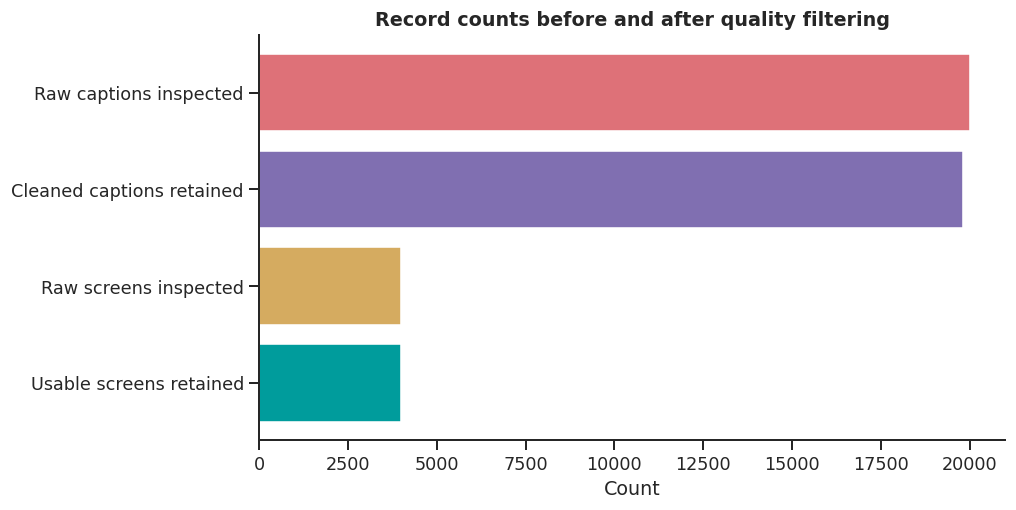

Clean dataset checks passed. The sample can now be split and featurised.


In [8]:
audit_file = CACHE / "load_audit.json"
if audit_file.exists():
    data_audit=json.loads(audit_file.read_text())
    details=pd.DataFrame(list(data_audit.items()),columns=["Loading or cleaning check","Count"])
    display(details)
    details.to_csv(TAB/"cleaning_impact.csv",index=False)
    fig,ax=plt.subplots(figsize=(9,4.6))
    steps={"Raw captions inspected":data_audit["raw_captions_checked"],
           "Cleaned captions retained":len(cap_table),
           "Raw screens inspected":data_audit["raw_screens_checked"],
           "Usable screens retained":len(screens)}
    names=list(steps);values=list(steps.values())
    ax.barh(names[::-1],values[::-1],color=["#009C9C","#D5AB60","#806FB1","#DE7178"])
    ax.set(xlabel="Count",title="Record counts before and after quality filtering")
    fig.tight_layout();show_plot(fig)
else:
    print("Loading audit file unavailable; regenerate the sample to recover raw counts.")

#explicit post cleaning checks before training.
assert screens.screenId.is_unique
assert cap_table.caption.str.strip().ne("").all()
assert screens.captions.map(len).min()>=1
assert all(Path(path).exists() for path in screens.image_path)
print("Clean dataset checks passed. The sample can now be split and featurised.")

## Manual review of 80 original screenshots before training


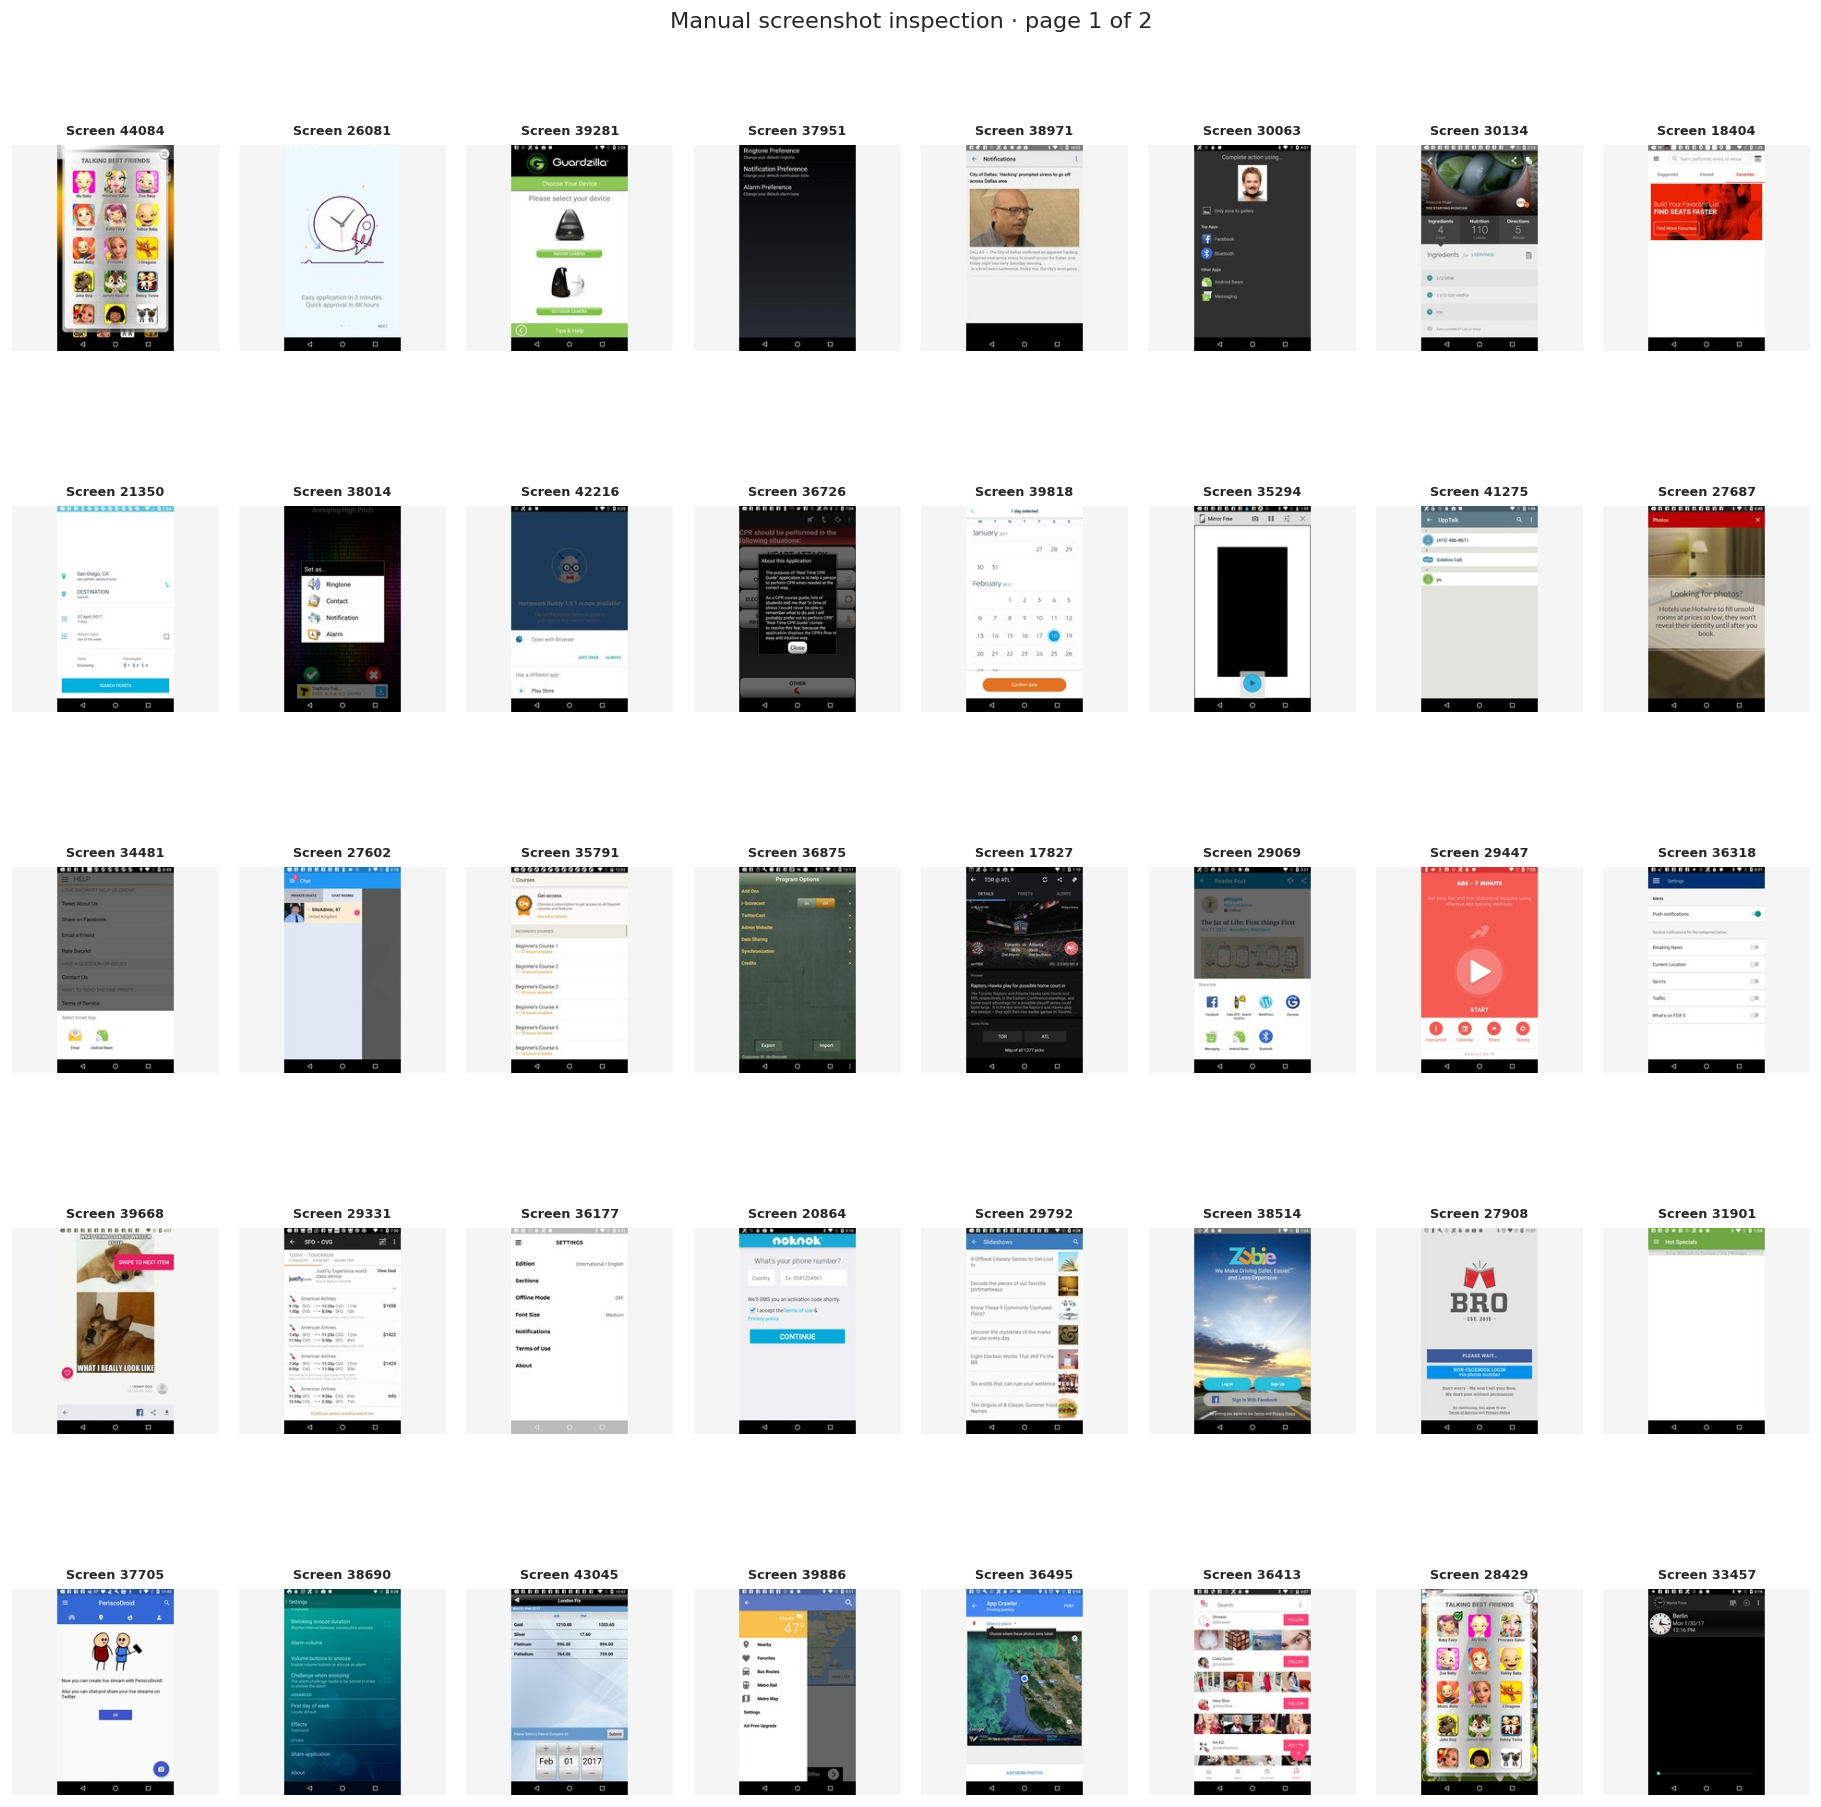

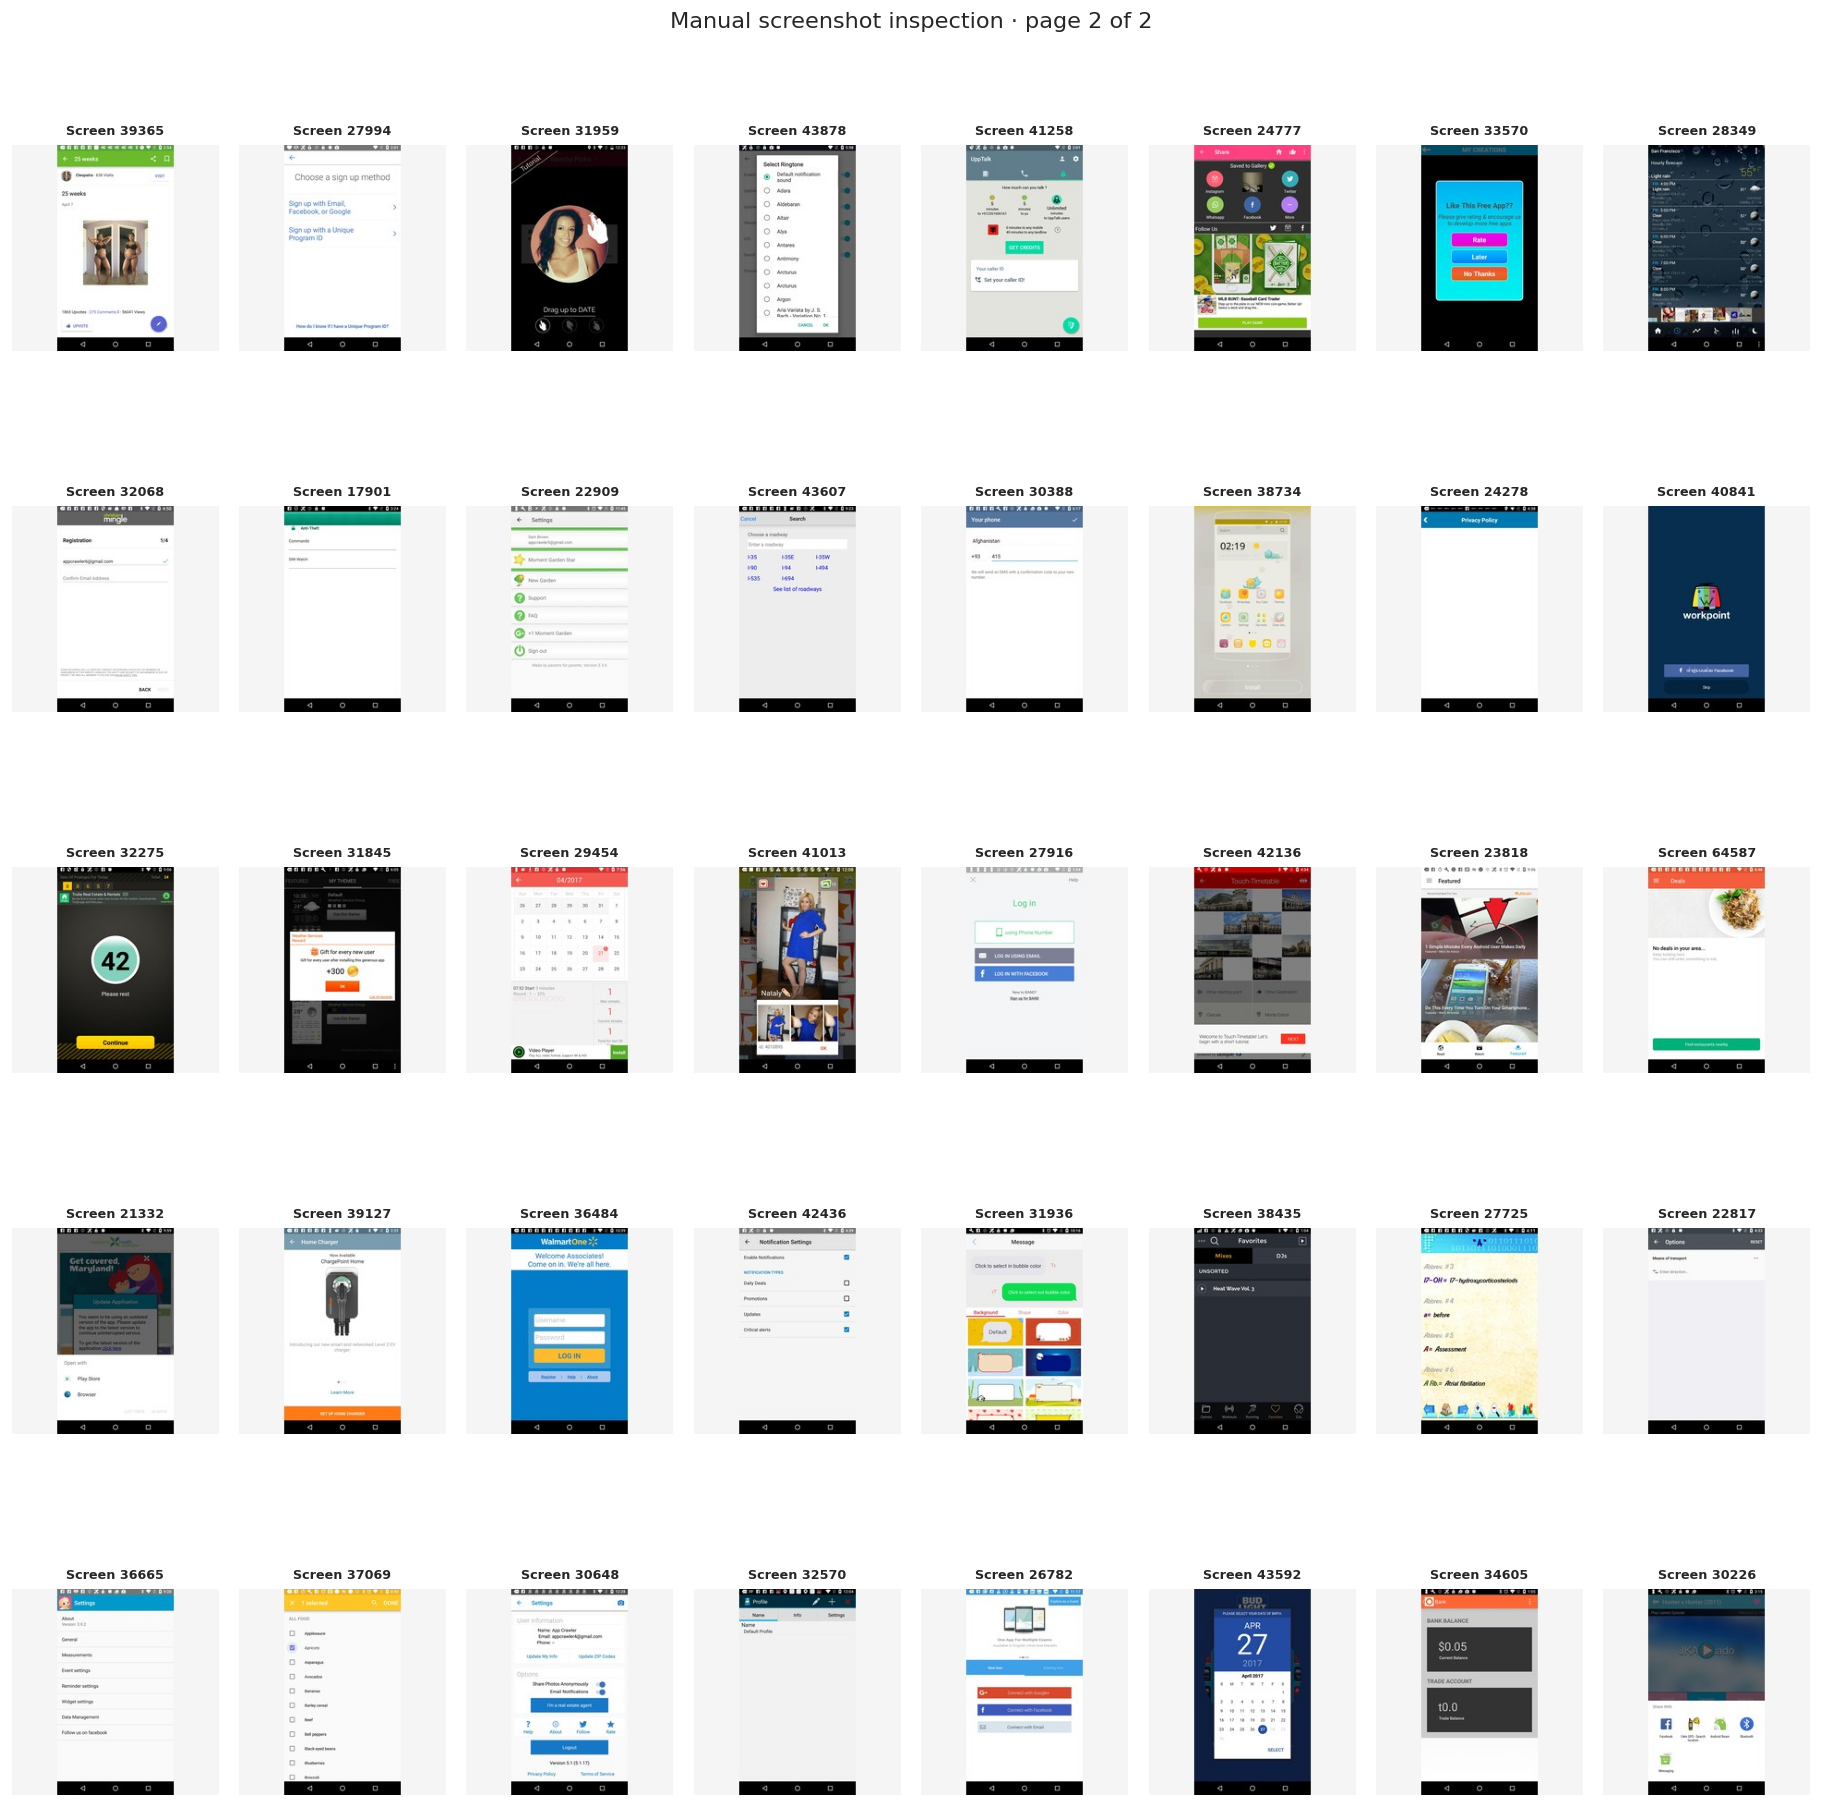

Human review: 80 screens inspected, 7 screens flagged.
Removed 7 reviewed screenshots before training. Screens remaining: 3993


In [9]:
# MANUAL CHECK
REVIEW_COMPLETED = True
FLAGGED_SCREEN_IDS = [38971, 30063, 27602, 31959, 39365, 41013, 30648]

review_count = min(80, len(screens))
review_rows = np.random.default_rng(SEED + 18).choice(
    len(screens), size=review_count, replace=False
)
review_screen_ids = screens.iloc[review_rows].screenId.astype(int).tolist()

for page in range(2):
    rows_on_page = review_rows[page * 40:(page + 1) * 40]
    fig, axes = plt.subplots(5, 8, figsize=(16, 17))
    for ax, position in zip(axes.flat, rows_on_page):
        item = screens.iloc[int(position)]
        with Image.open(item.image_path) as picture:
            ax.imshow(picture)
        ax.set_title(f"Screen {int(item.screenId)}", fontsize=8)
        ax.axis("off")
    for ax in list(axes.flat)[len(rows_on_page):]:
        ax.axis("off")
    fig.suptitle(f"Manual screenshot inspection · page {page + 1} of 2", fontsize=14)
    fig.tight_layout()
    show_plot(fig)

HUMAN_REVIEWED_SCREENS = review_count if REVIEW_COMPLETED else 0
HUMAN_REVIEWED_WITH_PII = len(FLAGGED_SCREEN_IDS) if REVIEW_COMPLETED else None

if REVIEW_COMPLETED:
    if review_count != 80:
        print("Warning: fewer than 80 screens were available for review.")
    if len(FLAGGED_SCREEN_IDS) != len(set(FLAGGED_SCREEN_IDS)):
        raise ValueError("A flagged ID was entered twice.")
    if not set(FLAGGED_SCREEN_IDS).issubset(set(review_screen_ids)):
        raise ValueError("Flagged IDs must come from the 80 screens shown above.")
    print(f"Human review: {HUMAN_REVIEWED_SCREENS} screens inspected, "
          f"{HUMAN_REVIEWED_WITH_PII} screens flagged.")
else:
    print("Manual inspection is NOT yet confirmed. Review both screenshot grids before reporting counts.")

if FLAGGED_SCREEN_IDS:
    screens = screens[~screens.screenId.isin(FLAGGED_SCREEN_IDS)].reset_index(drop=True)
    screens["screen_idx"] = np.arange(len(screens))
    caption_rows = [
        {"screen_idx": int(row.screen_idx), "caption": text, "norm": canonical(text)}
        for row in screens.itertuples() for text in row.captions
    ]
    cap_table = pd.DataFrame(caption_rows)
    cap_table["words"] = cap_table.caption.str.split().str.len()
    cap_table["characters"] = cap_table.caption.str.len()
    caption_owners = cap_table.groupby("norm")["screen_idx"].nunique()
    shared_keys = set(caption_owners[caption_owners > 1].index)
    cap_table["shared_description"] = cap_table.norm.isin(shared_keys)
    print(f"Removed {len(FLAGGED_SCREEN_IDS)} reviewed screenshots before training. "
          f"Screens remaining: {len(screens)}")


### Token lengths and truncation impact

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Median BERT tokens: 9
95th percentile: 12.0
Over the 16-token limit: 0.02%


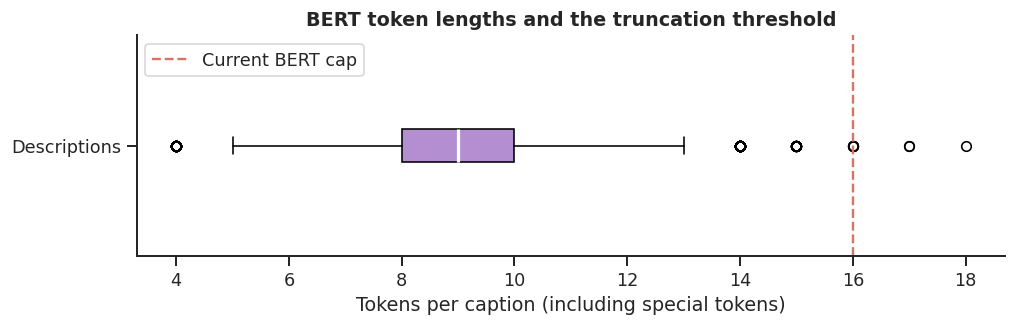

In [10]:
tokenizer_for_eda = AutoTokenizer.from_pretrained("bert-base-uncased")
unique_text_for_eda = cap_table.drop_duplicates("norm")["caption"].tolist()
lengths=[]
for first in range(0,len(unique_text_for_eda),512):
    items=unique_text_for_eda[first:first+512]
    ids=tokenizer_for_eda(items,add_special_tokens=True,truncation=False)["input_ids"]
    lengths.extend(len(row) for row in ids)
token_lengths=np.asarray(lengths)
token_truncation_pct=float((token_lengths>MAX_TEXT_TOKENS).mean()*100)
print("Median BERT tokens:",int(np.median(token_lengths)))
print("95th percentile:",round(np.percentile(token_lengths,95),1))
print(f"Over the {MAX_TEXT_TOKENS}-token limit: {token_truncation_pct:.2f}%")
fig,ax=plt.subplots(figsize=(9,3))
ax.boxplot(token_lengths,vert=False,patch_artist=True,
           boxprops={"facecolor":"#B38ED0"},medianprops={"color":"white","linewidth":2})
ax.axvline(MAX_TEXT_TOKENS,color="#D87562",linestyle="--",label="Current BERT cap")
ax.set(xlabel="Tokens per caption (including special tokens)",yticks=[1],
       yticklabels=["Descriptions"],title="BERT token lengths and the truncation threshold")
ax.legend();fig.tight_layout();show_plot(fig)
pd.DataFrame({"tokens":token_lengths}).to_csv(TAB/"bert_token_counts.csv",index=False)

## Extract frozen visual and text features (ResNet-50 and BERT)

In [11]:
class ScreenDataset(Dataset):
    def __init__(self, paths, transform):
        self.paths = list(paths)
        self.transform = transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, idx):
        with Image.open(self.paths[idx]) as image:
            return self.transform(image.convert("RGB"))

# ResNet-50
weights = models.ResNet50_Weights.DEFAULT
image_transform = weights.transforms()
feature_path = CACHE / "pretrained_features.npz"

unique_caption_texts = cap_table.drop_duplicates("norm").set_index("norm")["caption"]
unique_norms = unique_caption_texts.index.tolist()
caption_lookup = {text:i for i,text in enumerate(unique_norms)}
caption_to_unique = cap_table["norm"].map(caption_lookup).to_numpy(dtype=int)

use_cache = False
if feature_path.exists():
    data = np.load(feature_path)
    use_cache = (np.array_equal(data["screen_ids"], screens.screenId.to_numpy()) and
                 np.array_equal(data["caption_keys"], np.asarray(unique_norms)) and "cls" in data.files)
if use_cache:
    image_features = data["image"].astype("float32")
    unique_text_features = data["text"].astype("float32")
    unique_cls_features = data["cls"].astype("float32")
    print("Loaded frozen embeddings for the exact same screen IDs and captions.")
else:
    visual_base = models.resnet50(weights=weights)
    visual_encoder = nn.Sequential(*list(visual_base.children())[:-1]).to(DEVICE).eval()
    del visual_base
    loader = DataLoader(ScreenDataset(screens.image_path, image_transform),
                        batch_size=IMG_BATCH, shuffle=False, num_workers=2 if DEVICE=="cuda" else 0, pin_memory=(DEVICE=="cuda"))
    images_out = []
    start = seconds_now()
    with torch.inference_mode():
        for batch in tqdm(loader, desc="ResNet-50 image features"):
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE=="cuda")):
                features = visual_encoder(batch.to(DEVICE, non_blocking=True)).flatten(1)
            images_out.append(features.float().cpu().numpy())
    image_features = np.concatenate(images_out, axis=0).astype("float32")
    print("Image features extracted in", round(seconds_now()-start,1), "s")
    del visual_encoder
    torch.cuda.empty_cache()

    tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
    print(f"BERT texts above {MAX_TEXT_TOKENS} tokens: {token_truncation_pct:.2f}%")
    text_encoder = AutoModel.from_pretrained("bert-base-uncased").to(DEVICE).eval()
    text_out = []
    cls_out = []
    start = seconds_now()
    with torch.inference_mode():
        for k in tqdm(range(0, len(unique_norms), TEXT_BATCH), desc="BERT text features"):
            batch_text = unique_caption_texts.iloc[k:k+TEXT_BATCH].tolist()
            tokens = tokenizer(batch_text, return_tensors="pt", padding=True,
                               truncation=True, max_length=MAX_TEXT_TOKENS)
            tokens = {name:val.to(DEVICE) for name,val in tokens.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE=="cuda")):
                last = text_encoder(**tokens).last_hidden_state
                mask = tokens["attention_mask"].unsqueeze(-1)
                pooled = (last.float() * mask).sum(1) / mask.sum(1).clamp(min=1)
            text_out.append(pooled.cpu().numpy())
            cls_out.append(last[:,0,:].float().cpu().numpy())
    unique_text_features = np.concatenate(text_out, axis=0).astype("float32")
    unique_cls_features = np.concatenate(cls_out, axis=0).astype("float32")
    print("Text features extracted in", round(seconds_now()-start,1), "s")
    del text_encoder
    torch.cuda.empty_cache()
    np.savez_compressed(feature_path, image=image_features, text=unique_text_features, cls=unique_cls_features,
                        screen_ids=screens.screenId.to_numpy(),
                        caption_keys=np.asarray(unique_norms))

text_features = unique_text_features[caption_to_unique]
print("Image feature shape:", image_features.shape,
      "| Caption feature shape:", text_features.shape)
assert image_features.shape == (len(screens), 2048)
assert text_features.shape == (len(cap_table), 768)
assert np.isfinite(image_features).all() and np.isfinite(text_features).all()

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 180MB/s]


ResNet-50 image features:   0%|          | 0/84 [00:00<?, ?it/s]

Image features extracted in 14.4 s
BERT texts above 16 tokens: 0.02%


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT text features:   0%|          | 0/263 [00:00<?, ?it/s]

Text features extracted in 5.9 s
Image feature shape: (3993, 2048) | Caption feature shape: (19775, 768)


### Runtime and GPU feasibility check

In [12]:
feasibility = pd.DataFrame({
    "Item":["Sampled screenshots", "Retained descriptions", "Image embedding size (MB)",
            "Text embedding size (MB)", "Peak allocated GPU memory so far (GB)", "Compute device"],
    "Observed value":[len(screens),len(cap_table),
                      round(image_features.nbytes/1e6,2),round(text_features.nbytes/1e6,2),
                      round(torch.cuda.max_memory_allocated()/1e9,3) if DEVICE=="cuda" else None,
                      torch.cuda.get_device_name(0) if DEVICE=="cuda" else "CPU"]
})
display(feasibility)
feasibility.to_csv(TAB/"hardware_feature_feasibility.csv",index=False)

,Item,Observed value
0,Sampled screenshots,3993
1,Retained descriptions,19775
2,Image embedding size (MB),32.71
3,Text embedding size (MB),60.75
4,Peak allocated GPU memory so far (GB),0.476
5,Compute device,Tesla T4


## Split the data by app and near-identical screenshots

Perceptual hashes:   0%|          | 0/3993 [00:00<?, ?it/s]

Visual near-duplicate candidate edges: 827 | cross-app links: 568


,screens,distinct_apps,app_components
split,,,
test,351,131,122
train,3344,1227,974
validation,298,128,122


Cross-split near-identical pairs detected by the screening rule: 0
Test screens with ResNet cosine >= 0.95 to train/val: 11.97%
A high cosine-only rate can reflect visually similar but not identical UIs.


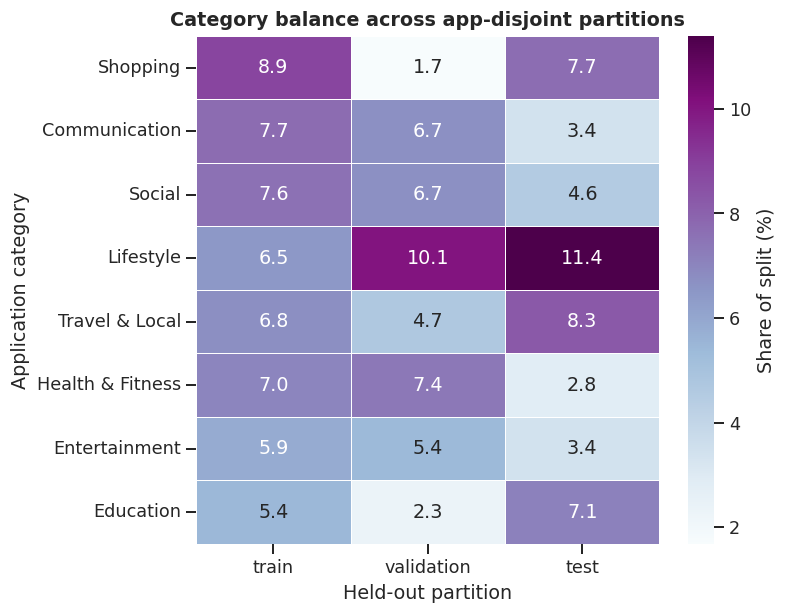

In [13]:
def perceptual_hash(path):
    with Image.open(path) as im:
        a = np.asarray(im.convert("L").resize((32,32)), dtype=np.float32)
    freqs = dctn(a, type=2, norm="ortho")[:8,:8].copy()
    threshold = np.median(freqs.flatten()[1:])
    return sum(int(value > threshold) << i for i,value in enumerate(freqs.flatten()))

hashes = [perceptual_hash(p) for p in tqdm(screens.image_path, desc="Perceptual hashes")]
normalized_images = F.normalize(torch.from_numpy(image_features), dim=1).numpy()
similarity = normalized_images @ normalized_images.T
np.fill_diagonal(similarity, -1.0)

app_names = screens.app.to_list()
app_parent = {name:name for name in set(app_names)}
def find_app(x):
    while app_parent[x] != x:
        app_parent[x] = app_parent[app_parent[x]]
        x = app_parent[x]
    return x

def merge_apps(a, b):
    pa, pb = find_app(a), find_app(b)
    if pa != pb: app_parent[pb] = pa

num_edges, cross_app_edges = 0, 0
seen_near_pairs = set()
k_neighbors = min(15, len(screens)-1)
for i in range(len(screens)):
    nearest = np.argpartition(similarity[i], -k_neighbors)[-k_neighbors:]
    for j in nearest:
        j = int(j)
        if j == i or similarity[i,j] < .95: continue
        pair = (min(i,j), max(i,j))
        if pair in seen_near_pairs: continue
        seen_near_pairs.add(pair)
        distance = (hashes[i] ^ hashes[j]).bit_count()
        if distance <= 8:
            num_edges += 1
            if app_names[i] != app_names[j]:
                cross_app_edges += 1
                merge_apps(app_names[i], app_names[j])

screens["group"] = [find_app(name) for name in app_names]
all_img = np.arange(len(screens))
group_split = GroupShuffleSplit(n_splits=1, test_size=.20, random_state=SEED)
train_idx, temp_idx = next(group_split.split(all_img, groups=screens.group))
split2 = GroupShuffleSplit(n_splits=1, test_size=.50, random_state=SEED+1)
val_local, test_local = next(split2.split(temp_idx, groups=screens.group.iloc[temp_idx]))
val_idx = temp_idx[val_local]
test_idx = temp_idx[test_local]

screens["split"] = "unassigned"
for split_name, ids in [("train",train_idx),("validation",val_idx),("test",test_idx)]:
    screens.loc[ids, "split"] = split_name
assert screens.split.ne("unassigned").all()
for a,b in [(train_idx,val_idx),(train_idx,test_idx),(val_idx,test_idx)]:
    assert set(screens.group.iloc[a]).isdisjoint(set(screens.group.iloc[b]))

split_counts = screens.groupby("split").agg(screens=("screenId","size"),
                                             distinct_apps=("app","nunique"),
                                             app_components=("group","nunique"))
print(f"Visual near-duplicate candidate edges: {num_edges} | cross-app links: {cross_app_edges}")
display(split_counts)
(split_counts).to_csv(TAB / "03_split_summary.csv")
screens[["screenId","app","category","split","group"]].to_csv(TAB / "04_split_ids.csv",index=False)

# Audit test→train/validation
not_test = np.r_[train_idx,val_idx]
near_misses = []
for i in test_idx:
    nearest = not_test[np.argsort(similarity[i,not_test])[-15:]]
    for j in nearest:
        if similarity[i,j] >= .95 and (hashes[int(i)] ^ hashes[int(j)]).bit_count() <= 8:
            near_misses.append((int(i),int(j)))
print("Cross-split near-identical pairs detected by the screening rule:", len(near_misses))
# Count high-cosine cross-split candidates
cosine_only = (similarity[np.ix_(test_idx, not_test)] >= .95).any(axis=1).mean() * 100
print(f"Test screens with ResNet cosine >= 0.95 to train/val: {cosine_only:.2f}%")
print("A high cosine-only rate can reflect visually similar but not identical UIs.")
if near_misses:
    print("WARNING: investigate detected duplicate leakage before using these results.")
assert len(train_idx) >= 150 and len(val_idx) >= 60 and len(test_idx) >= 60, "Split too small: increase N_SCREENS."

top_categories = screens.category.value_counts().head(8).index
heat = pd.crosstab(screens.category, screens.split, normalize="columns").reindex(top_categories).fillna(0)*100
heat = heat.reindex(columns=["train","validation","test"])
fig, ax = plt.subplots(figsize=(7,5.5))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="BuPu", linewidths=.5,
            cbar_kws={"label":"Share of split (%)"}, ax=ax)
ax.set(xlabel="Held-out partition",ylabel="Application category",
       title="Category balance across app-disjoint partitions")
fig.tight_layout(); show_plot(fig)
del similarity

## Model comparison

In [14]:
img_train_ids = np.asarray(train_idx, dtype=int)
caption_img_ids = cap_table.screen_idx.to_numpy(dtype=int)
train_cap_ids = np.flatnonzero(np.isin(caption_img_ids, img_train_ids))
val_cap_ids = np.flatnonzero(np.isin(caption_img_ids, val_idx))
test_cap_ids = np.flatnonzero(np.isin(caption_img_ids, test_idx))

def fit_feature_pipeline(features, train_rows, target_dim=FEATURE_DIM):
    pre = StandardScaler().fit(features[train_rows])
    x_train = pre.transform(features[train_rows])
    dim = min(target_dim, x_train.shape[0]-1, x_train.shape[1])
    pca = PCA(n_components=dim, svd_solver="randomized", random_state=SEED)
    pca.fit(x_train)
    projected_train = pca.transform(x_train)
    post = StandardScaler().fit(projected_train)
    transformed = post.transform(pca.transform(pre.transform(features)))
    return np.clip(transformed, -6, 6).astype("float32"), (pre, pca, post)

Xi, visual_pipeline = fit_feature_pipeline(image_features, train_idx)
Xt, text_pipeline = fit_feature_pipeline(text_features, train_cap_ids)
assert Xi.shape[0] == len(screens) and Xt.shape[0] == len(cap_table)
assert Xi.shape[1] == Xt.shape[1]
D = Xi.shape[1]
print("Fusion dimension:", D)
print("Image PCA explained variance:", round(sum(visual_pipeline[1].explained_variance_ratio_)*100,1),"%")
print("Text PCA explained variance:", round(sum(text_pipeline[1].explained_variance_ratio_)*100,1),"%")

image_caption_sets = defaultdict(set)
for row in cap_table.itertuples(): image_caption_sets[row.screen_idx].add(row.norm)
image_caption_rows = defaultdict(list)
for j,i in enumerate(caption_img_ids): image_caption_rows[int(i)].append(int(j))

def make_gallery(img_ids):
    img_ids = np.asarray(img_ids,dtype=int)
    cap_ids = np.flatnonzero(np.isin(caption_img_ids,img_ids))
    normals = cap_table.norm.iloc[cap_ids].tolist()
    to_local = {int(gid):i for i,gid in enumerate(img_ids)}
    pos = np.zeros((len(img_ids),len(cap_ids)), dtype=bool)
    for col, owner in enumerate(caption_img_ids[cap_ids]):
        pos[to_local[int(owner)], col] = True
    relaxed = pos.copy()
    norm_to_imgs = defaultdict(list)
    for global_img in img_ids:
        for key in image_caption_sets[int(global_img)]:
            norm_to_imgs[key].append(to_local[int(global_img)])
    for col, key in enumerate(normals):
        relaxed[norm_to_imgs[key], col] = True
    assert pos.any(axis=1).all() and pos.any(axis=0).all()
    return {"img_ids":img_ids,"cap_ids":cap_ids,
            "img":Xi[img_ids],"txt":Xt[cap_ids],
            "pos":pos,"pos_relaxed":relaxed,
            "categories":screens.category.iloc[img_ids].to_numpy(),
            "caption_img":caption_img_ids[cap_ids], "norm":normals}

TRAIN = make_gallery(train_idx)
VAL = make_gallery(val_idx)
TEST = make_gallery(test_idx)
print("Fixed gallery sizes (images, captions):")
for name,g in [("Train",TRAIN),("Validation",VAL),("Test",TEST)]:
    print(f"{name:10}: {len(g['img_ids']):5} images, {len(g['cap_ids']):6} descriptions")

Fusion dimension: 128
Image PCA explained variance: 59.6 %
Text PCA explained variance: 87.2 %
Fixed gallery sizes (images, captions):
Train     :  3344 images,  16575 descriptions
Validation:   298 images,   1475 descriptions
Test      :   351 images,   1725 descriptions


## Retrieval metrics and interpretation

In [15]:
def first_positive_rank(scores, positives):
    """1-based rank of the highest-scoring relevant candidate in each row."""
    scores = np.asarray(scores, dtype=np.float32)
    assert scores.shape == positives.shape
    assert positives.any(axis=1).all(), "Every query needs a relevant candidate"
    best_relevant = np.max(np.where(positives, scores, -np.inf), axis=1)
    outrank = (scores > best_relevant[:, None]).sum(axis=1)
    tied_wrong = ((scores == best_relevant[:, None]) & ~positives).sum(axis=1)
    return 1.0 + outrank + 0.5 * tied_wrong

def metrics_from_ranks(ranks):
    ranks = np.asarray(ranks)
    return {"R@1":float(np.mean(ranks <= 1)*100),
            "R@5":float(np.mean(ranks <= 5)*100),
            "R@10":float(np.mean(ranks <= 10)*100),
            "MRR":float(np.mean(1/ranks)),
            "MedR":float(np.median(ranks))}

def evaluate_scores(image_to_caption, positives, caption_to_image=None):
    """Return both directions; optional separate t→i scores for reranking."""
    if caption_to_image is None: caption_to_image = image_to_caption.T
    ri = first_positive_rank(image_to_caption, positives)
    rt = first_positive_rank(caption_to_image, positives.T)
    mi = metrics_from_ranks(ri)
    mt = metrics_from_ranks(rt)
    return {"Screen→Text":mi, "Text→Screen":mt,
            "Average R@10":(mi["R@10"]+mt["R@10"])/2,
            "rank_i2t":ri,"rank_t2i":rt}

def record_metrics(name, result, seconds):
    return {"Method":name,
            "Screen→Text R@1":result["Screen→Text"]["R@1"],
            "Screen→Text R@5":result["Screen→Text"]["R@5"],
            "Screen→Text R@10":result["Screen→Text"]["R@10"],
            "Screen→Text MRR":result["Screen→Text"]["MRR"],
            "Screen→Text MedR":result["Screen→Text"]["MedR"],
            "Text→Screen R@1":result["Text→Screen"]["R@1"],
            "Text→Screen R@5":result["Text→Screen"]["R@5"],
            "Text→Screen R@10":result["Text→Screen"]["R@10"],
            "Text→Screen MRR":result["Text→Screen"]["MRR"],
            "Text→Screen MedR":result["Text→Screen"]["MedR"],
            "Average R@10":result["Average R@10"],
            "Ranking seconds":round(float(seconds), 3)}

# Sanity test: two captions match one image, so it succeeds at rank 1.
toy_scores = np.array([[.9,.7,.1],[.2,.3,.8]])
toy_matches = np.array([[True,True,False],[False,False,True]])
assert np.array_equal(first_positive_rank(toy_scores,toy_matches),[1,1])
# A constant scorer should NOT receive rank 1 for every query.
assert first_positive_rank(np.zeros((1,3)), np.array([[True,False,False]]))[0] > 1
print("Multi-positive and tie-aware retrieval metric sanity tests: PASS")

Multi-positive and tie-aware retrieval metric sanity tests: PASS


## Random reference and ridge-regression baseline

In [16]:
def norm_rows(values):
    return values / np.maximum(np.linalg.norm(values, axis=1, keepdims=True), 1e-8)

ridge_choices = []
for alpha in [1.0, 10.0, 20.0, 100.0, 1000.0]:
    candidate = Ridge(alpha=alpha)
    candidate.fit(Xt[train_cap_ids], Xi[caption_img_ids[train_cap_ids]])
    val_prediction = candidate.predict(VAL["txt"])
    val_scores = norm_rows(VAL["img"]) @ norm_rows(val_prediction).T
    val_metrics = evaluate_scores(val_scores, VAL["pos"])
    ridge_choices.append({"alpha":alpha,"validation_average_R10":val_metrics["Average R@10"]})
ridge_table = pd.DataFrame(ridge_choices)
display(ridge_table.round(2))
ridge_table.to_csv(TAB/"ridge_regularisation_validation.csv",index=False)
BEST_RIDGE_ALPHA = float(ridge_table.sort_values(["validation_average_R10","alpha"],
                                            ascending=[False,True]).iloc[0]["alpha"])
ridge_start = seconds_now()
ridge = Ridge(alpha=BEST_RIDGE_ALPHA)
ridge.fit(Xt[train_cap_ids], Xi[caption_img_ids[train_cap_ids]])
ridge_training_s = seconds_now()-ridge_start
print("Validation-selected ridge alpha:",BEST_RIDGE_ALPHA)

def ridge_scores(gallery):
    start = seconds_now()
    scores = norm_rows(gallery["img"]) @ norm_rows(ridge.predict(gallery["txt"])).T
    return scores.astype("float32"),seconds_now()-start

rng_random = np.random.default_rng(SEED)
random_val = rng_random.random(VAL["pos"].shape, dtype=np.float32)
random_test = rng_random.random(TEST["pos"].shape, dtype=np.float32)
ridge_val, ridge_val_s = ridge_scores(VAL)
ridge_test, ridge_test_s = ridge_scores(TEST)
print("Ridge validation mean R@10:",round(evaluate_scores(ridge_val,VAL["pos"])["Average R@10"],2))


,alpha,validation_average_R10
0,1.0,23.14
1,10.0,23.14
2,20.0,23.14
3,100.0,23.14
4,1000.0,23.14


Validation-selected ridge alpha: 1.0
Ridge validation mean R@10: 23.14


### BERT representation check: mean pooling versus [CLS]

,Text pooling,Validation average R@10 (%)
0,BERT mean,23.14
1,BERT [CLS],22.86


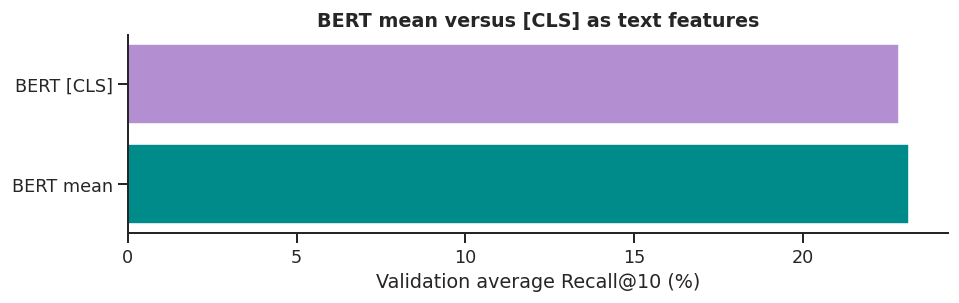

Main fusion models use mean pooling, as specified in the proposal.


In [17]:
# Two BERT representations, one frozen encoder, train-only PCA and scaling.
cls_features = unique_cls_features[caption_to_unique]
CLS_Xt,_ = fit_feature_pipeline(cls_features,train_cap_ids)
cls_baseline = Ridge(alpha=BEST_RIDGE_ALPHA)
cls_baseline.fit(CLS_Xt[train_cap_ids],Xi[caption_img_ids[train_cap_ids]])
cls_val_scores = norm_rows(VAL["img"]) @ norm_rows(
    cls_baseline.predict(CLS_Xt[VAL["cap_ids"]])).T
mean_val_result = evaluate_scores(ridge_val,VAL["pos"])
cls_val_result = evaluate_scores(cls_val_scores,VAL["pos"])
pool_table = pd.DataFrame({
 "Text pooling":["BERT mean", "BERT [CLS]"],
 "Validation average R@10 (%)":[mean_val_result["Average R@10"],
                                 cls_val_result["Average R@10"]]
})
display(pool_table.round(2))
pool_table.to_csv(TAB/"bert_pooling_validation.csv",index=False)
fig,ax=plt.subplots(figsize=(8.5,2.8))
ax.barh(pool_table["Text pooling"],pool_table["Validation average R@10 (%)"],
        color=["#008B8B","#B38ED0"])
ax.set(xlabel="Validation average Recall@10 (%)",
       title="BERT mean versus [CLS] as text features")
fig.tight_layout();show_plot(fig)
print("Main fusion models use mean pooling, as specified in the proposal.")

## Contrastive fusion: dual encoder with multi-positive InfoNCE

In [18]:
class DualEncoder(nn.Module):
    def __init__(self, dim=D, hidden=256, out_dim=96, dropout=.20):
        super().__init__()
        self.image_head = nn.Sequential(nn.Linear(dim,hidden),nn.ReLU(),nn.Dropout(dropout),nn.Linear(hidden,out_dim))
        self.text_head  = nn.Sequential(nn.Linear(dim,hidden),nn.ReLU(),nn.Dropout(dropout),nn.Linear(hidden,out_dim))
        self.log_temperature = nn.Parameter(torch.tensor(math.log(0.07)))
    def forward(self, images, texts):
        vi = F.normalize(self.image_head(images), dim=-1)
        vt = F.normalize(self.text_head(texts), dim=-1)
        temperature = self.log_temperature.exp().clamp(.03, .30)
        return (vi @ vt.T)/temperature

@torch.inference_mode()
def dual_scores(model, gallery):
    model.eval()
    start = seconds_now()
    image_tensor = torch.from_numpy(gallery["img"]).to(DEVICE)
    text_tensor = torch.from_numpy(gallery["txt"]).to(DEVICE)
    vi = F.normalize(model.image_head(image_tensor), dim=1)
    vt = F.normalize(model.text_head(text_tensor), dim=1)
    scores = (vi @ vt.T).float().cpu().numpy()
    return scores, seconds_now()-start

def multi_positive_infonce(logits, positive_mask):
    """Contrastive loss with ANY true matching descriptions as positives."""
    def one_direction(logits_, mask_):
        positive_score = torch.logsumexp(logits_.masked_fill(~mask_,float("-inf")),dim=1)
        all_score = torch.logsumexp(logits_,dim=1)
        return (all_score-positive_score).mean()
    return .5*(one_direction(logits,positive_mask)+one_direction(logits.T,positive_mask.T))

# Compare TRAIN and VALIDATION at a matched number of screens.
audit_n = min(350, len(train_idx),len(val_idx))
audit_rng = np.random.default_rng(SEED)
TRAIN_AUDIT = make_gallery(audit_rng.choice(train_idx,size=audit_n,replace=False))
VAL_AUDIT = make_gallery(audit_rng.choice(val_idx,size=audit_n,replace=False))

img_t = torch.from_numpy(Xi).to(DEVICE)
txt_t = torch.from_numpy(Xt).to(DEVICE)

def train_dual(seed):
    set_seed(seed)
    model = DualEncoder().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(),lr=0.001,weight_decay=1e-3)
    best_score,best_epoch,best_weights = -1,0,None
    no_improvement = 0
    history = []
    local_rng = np.random.default_rng(seed)
    start = seconds_now()
    for epoch in range(1,CONTRASTIVE_EPOCHS+1):
        model.train()
        order = local_rng.permutation(train_idx)
        losses = []
        for beginning in range(0,len(order),BATCH_SIZE):
            image_ids = order[beginning:beginning+BATCH_SIZE]
            if len(image_ids)<2: continue
            selected_captions = np.concatenate([image_caption_rows[int(i)] for i in image_ids]).astype(int)
            current_texts = cap_table.norm.iloc[selected_captions].tolist()
            positive = np.array([[text in image_caption_sets[int(image_id)]
                                  for text in current_texts] for image_id in image_ids],dtype=bool)
            positive = torch.from_numpy(positive).to(DEVICE)
            logits = model(img_t[image_ids],txt_t[selected_captions])
            loss = multi_positive_infonce(logits,positive)
            optimizer.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),max_norm=1.0)
            optimizer.step()
            losses.append(loss.item())
        train_s,_ = dual_scores(model,TRAIN_AUDIT)
        val_s,_ = dual_scores(model,VAL_AUDIT)
        tr_recall = evaluate_scores(train_s,TRAIN_AUDIT["pos"])["Average R@10"]
        va_recall = evaluate_scores(val_s,VAL_AUDIT["pos"])["Average R@10"]
        history.append({"seed":seed,"epoch":epoch,"train_loss":np.mean(losses),
                        "train_R10":tr_recall,"val_R10":va_recall})
        if va_recall > best_score + 0.01:
            best_score,best_epoch = va_recall,epoch
            best_weights = copy.deepcopy(model.state_dict())
            no_improvement = 0
        else:
            no_improvement += 1
        print(f"Seed {seed} | epoch {epoch:02d} | InfoNCE {np.mean(losses):.3f} | "
              f"train R@10 {tr_recall:.1f}% | val R@10 {va_recall:.1f}%")
        if no_improvement >= PATIENCE:
            print("Early stopped after",epoch,"epochs")
            break
    model.load_state_dict(best_weights)
    return {"model":model,"history":pd.DataFrame(history),"best_epoch":best_epoch,
            "val_audit_R10":best_score,"seconds":seconds_now()-start,"seed":seed}

dual_runs = [train_dual(seed) for seed in TRAIN_SEEDS]
selected_run = max(dual_runs, key=lambda result:result["val_audit_R10"])
dual_model = selected_run["model"]
dual_val,dual_val_s = dual_scores(dual_model,VAL)
print("Selected seed:",selected_run["seed"],"| best validation epoch:",selected_run["best_epoch"])
for run in dual_runs:
    run["history"].to_csv(TAB/f"05_dual_history_seed_{run['seed']}.csv",index=False)
torch.save(dual_model.state_dict(),OUT/"best_dual_encoder.pt")

Seed 42 | epoch 01 | InfoNCE 4.415 | train R@10 27.5% | val R@10 14.5%
Seed 42 | epoch 02 | InfoNCE 3.717 | train R@10 42.5% | val R@10 20.9%
Seed 42 | epoch 03 | InfoNCE 3.380 | train R@10 50.1% | val R@10 21.2%
Seed 42 | epoch 04 | InfoNCE 3.155 | train R@10 55.5% | val R@10 22.1%
Seed 42 | epoch 05 | InfoNCE 2.969 | train R@10 64.5% | val R@10 22.5%
Seed 42 | epoch 06 | InfoNCE 2.816 | train R@10 68.7% | val R@10 23.1%
Seed 42 | epoch 07 | InfoNCE 2.683 | train R@10 72.1% | val R@10 22.8%
Seed 42 | epoch 08 | InfoNCE 2.559 | train R@10 75.3% | val R@10 23.4%
Seed 42 | epoch 09 | InfoNCE 2.451 | train R@10 77.6% | val R@10 23.1%
Seed 42 | epoch 10 | InfoNCE 2.371 | train R@10 78.6% | val R@10 22.6%
Seed 42 | epoch 11 | InfoNCE 2.255 | train R@10 80.9% | val R@10 23.6%
Seed 42 | epoch 12 | InfoNCE 2.197 | train R@10 81.4% | val R@10 22.8%
Seed 42 | epoch 13 | InfoNCE 2.117 | train R@10 84.0% | val R@10 21.8%
Seed 42 | epoch 14 | InfoNCE 2.052 | train R@10 84.4% | val R@10 22.7%
Seed 4

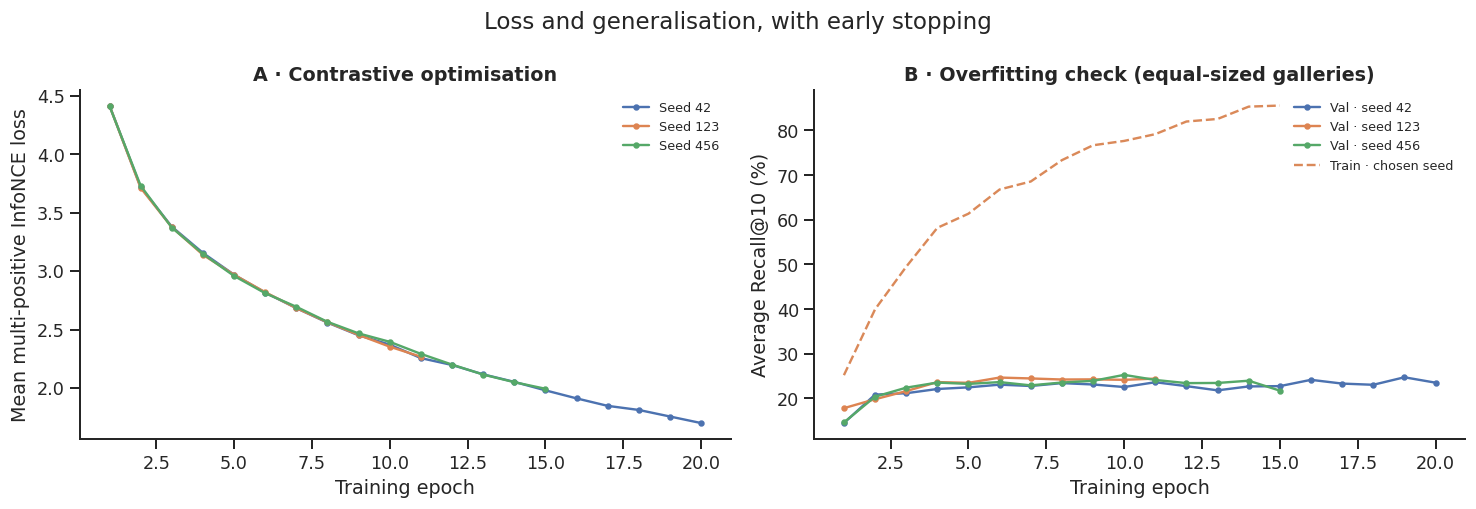

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13,4.5))
for run in dual_runs:
    hist = run["history"]
    axes[0].plot(hist.epoch,hist.train_loss,marker="o",ms=3,label=f"Seed {run['seed']}")
    axes[1].plot(hist.epoch,hist.val_R10,marker="o",ms=3,label=f"Val · seed {run['seed']}")
    if run["seed"] == selected_run["seed"]:
        axes[1].plot(hist.epoch,hist.train_R10,ls="--",color="#DA8959",label="Train · chosen seed")
axes[0].set(xlabel="Training epoch",ylabel="Mean multi-positive InfoNCE loss",
            title="A · Contrastive optimisation")
axes[1].set(xlabel="Training epoch",ylabel="Average Recall@10 (%)",
            title="B · Overfitting check (equal-sized galleries)")
for ax in axes:ax.legend(frameon=False,fontsize=8)
fig.suptitle("Loss and generalisation, with early stopping")
fig.tight_layout();show_plot(fig)

## Early fusion

Training pair examples: (49725, 3) | positive fraction: 0.333
Early fusion | epoch 01: train BCE 0.643; val BCE 0.631
Early fusion | epoch 02: train BCE 0.629; val BCE 0.627
Early fusion | epoch 03: train BCE 0.615; val BCE 0.614
Early fusion | epoch 04: train BCE 0.583; val BCE 0.602
Early fusion | epoch 05: train BCE 0.541; val BCE 0.592
Early fusion | epoch 06: train BCE 0.501; val BCE 0.595
Early fusion | epoch 07: train BCE 0.466; val BCE 0.621
Early fusion | epoch 08: train BCE 0.443; val BCE 0.625
Early fusion | epoch 09: train BCE 0.417; val BCE 0.652
Early fusion | epoch 10: train BCE 0.398; val BCE 0.654
Best early-fusion epoch: 5 | training seconds: 7.5


Pairwise fusion scoring:   0%|          | 0/25 [00:00<?, ?it/s]

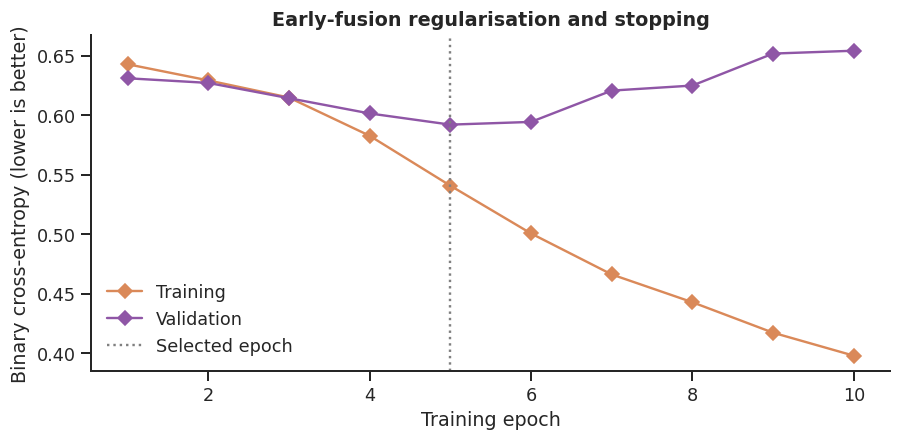

In [20]:
class EarlyFusionMLP(nn.Module):
    def __init__(self, dim=D):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(dim*4,160),nn.ReLU(),nn.Dropout(.30),
                                 nn.Linear(160,48),nn.ReLU(),nn.Linear(48,1))
    def forward(self, image_vectors, text_vectors):
        combined = torch.cat([image_vectors,text_vectors,
                              torch.abs(image_vectors-text_vectors),
                              image_vectors*text_vectors],dim=-1)
        return self.net(combined).flatten()

def make_pair_examples(screen_ids, seed):
    rng = np.random.default_rng(seed)
    screen_ids = np.asarray(screen_ids, dtype=int)
    screen_set = set(screen_ids)
    cap_ids = np.flatnonzero(np.isin(caption_img_ids,screen_ids))
    category_to_imgs = defaultdict(list)
    for img_id in screen_ids:
        category_to_imgs[screens.category.iloc[img_id]].append(int(img_id))
    rows = []
    for c in cap_ids:
        i = int(caption_img_ids[c]); norm = cap_table.norm.iloc[c]
        rows.append((i,int(c),1.0))
        candidates = category_to_imgs[screens.category.iloc[i]]
        choices = [q for q in candidates if norm not in image_caption_sets[q]]
        if not choices:
            choices = [int(q) for q in screen_ids if norm not in image_caption_sets[int(q)]]
        if choices:
            rows.append((int(rng.choice(choices)),int(c),0.0))
        for _ in range(25):
            other = int(rng.choice(cap_ids))
            if cap_table.norm.iloc[other] not in image_caption_sets[i]:
                rows.append((i,other,0.0))
                break
    rng.shuffle(rows)
    return np.asarray(rows,dtype=np.float64)

train_pairs = make_pair_examples(train_idx, SEED)
val_pairs = make_pair_examples(val_idx, SEED+1)
print("Training pair examples:",train_pairs.shape,"| positive fraction:",round(train_pairs[:,2].mean(),3))

def pair_loader(pairs, batch_size=512, shuffle=False):
    dataset = TensorDataset(torch.from_numpy(pairs[:,0].astype("int64")),
                            torch.from_numpy(pairs[:,1].astype("int64")),
                            torch.from_numpy(pairs[:,2].astype("float32")))
    return DataLoader(dataset,batch_size=batch_size,shuffle=shuffle)

train_loader = pair_loader(train_pairs,shuffle=True)
val_loader = pair_loader(val_pairs)
set_seed(SEED)
early_model = EarlyFusionMLP().to(DEVICE)
early_optimizer = torch.optim.AdamW(early_model.parameters(),lr=0.0008,weight_decay=0.002)
criterion = nn.BCEWithLogitsLoss()

best_val_loss = float("inf")
best_epoch,best_state,stale = 0,None,0
early_log = []
early_start = seconds_now()
for epoch in range(1,EARLY_EPOCHS+1):
    epoch_loss = []
    early_model.train()
    for ii,jj,yy in train_loader:
        logits = early_model(img_t[ii.to(DEVICE)],txt_t[jj.to(DEVICE)])
        loss = criterion(logits,yy.to(DEVICE))
        early_optimizer.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(early_model.parameters(),1.0)
        early_optimizer.step()
        epoch_loss.append(loss.item())
    early_model.eval()
    validation_loss = []
    with torch.inference_mode():
        for ii,jj,yy in val_loader:
            pred = early_model(img_t[ii.to(DEVICE)],txt_t[jj.to(DEVICE)])
            validation_loss.append(criterion(pred,yy.to(DEVICE)).item())
    training_loss = float(np.mean(epoch_loss))
    validation_loss = float(np.mean(validation_loss))
    early_log.append({"epoch":epoch,"train_BCE":training_loss,"val_BCE":validation_loss})
    print(f"Early fusion | epoch {epoch:02d}: train BCE {training_loss:.3f}; val BCE {validation_loss:.3f}")
    if validation_loss < best_val_loss-0.0005:
        best_val_loss,best_epoch = validation_loss,epoch
        best_state = copy.deepcopy(early_model.state_dict())
        stale = 0
    else:
        stale += 1
    if stale >= PATIENCE:break
early_model.load_state_dict(best_state)
early_training_s = seconds_now()-early_start
pd.DataFrame(early_log).to_csv(TAB/"06_early_fusion_history.csv",index=False)
torch.save(early_model.state_dict(),OUT/"best_early_fusion.pt")
print("Best early-fusion epoch:",best_epoch,"| training seconds:",round(early_training_s,1))

@torch.inference_mode()
def score_early_gallery(model, gallery, img_chunk=12, cap_chunk=256):
    """Score EVERY pair; small chunks avoid large CUDA memory use."""
    model.eval()
    start = seconds_now()
    a = torch.from_numpy(gallery["img"]).to(DEVICE)
    b = torch.from_numpy(gallery["txt"]).to(DEVICE)
    scores = np.empty((len(a),len(b)),dtype=np.float32)
    for i in tqdm(range(0,len(a),img_chunk),desc="Pairwise fusion scoring"):
        av = a[i:i+img_chunk]
        for j in range(0,len(b),cap_chunk):
            bv = b[j:j+cap_chunk]
            x = av.repeat_interleave(len(bv),dim=0)
            y = bv.repeat(len(av),1)
            logits = model(x,y).reshape(len(av),len(bv))
            scores[i:i+len(av),j:j+len(bv)] = logits.float().cpu().numpy()
    return scores, seconds_now()-start

early_val,early_val_s = score_early_gallery(early_model,VAL)
fig,ax=plt.subplots(figsize=(8,4))
early_hist = pd.DataFrame(early_log)
ax.plot(early_hist.epoch,early_hist.train_BCE,marker="D",color="#DA8959",label="Training")
ax.plot(early_hist.epoch,early_hist.val_BCE,marker="D",color="#8F56A6",label="Validation")
ax.axvline(best_epoch,ls=":",c="gray",label="Selected epoch")
ax.set(xlabel="Training epoch",ylabel="Binary cross-entropy (lower is better)",
       title="Early-fusion regularisation and stopping")
ax.legend(frameon=False);fig.tight_layout();show_plot(fig)

## fast retrieval followed by reranking

In [21]:
def reorder_topk(base_scores, early_scores, k=RETRIEVAL_TOP_K, alpha=.5):
    """Rescore only dual top-k, leaving the other candidates below them."""
    scores = base_scores.copy()
    n_query,n_candidates = scores.shape
    k = min(k,n_candidates)
    for row in range(n_query):
        candidates = np.argpartition(base_scores[row], -k)[-k:]
        base = base_scores[row,candidates]
        extra = early_scores[row,candidates]
        #Per-query standardisation avoids mixing incompatible logit/cosine scales.
        a = (base-base.mean())/(base.std()+1e-6)
        b = (extra-extra.mean())/(extra.std()+1e-6)
        blended = alpha*a+(1-alpha)*b
        # All original top-k candidates stay ahead of candidates outside the shortlist.
        lower_boundary = base_scores[row, np.argpartition(base_scores[row],-k)[-k]]
        blended = (blended-blended.min())/(np.ptp(blended)+1e-6)
        scores[row,candidates] = lower_boundary + .0001 + blended*.01
    return scores

def hybrid_pair(base,early,positive,k=RETRIEVAL_TOP_K,alpha=.5):
    i2t = reorder_topk(base,early,k=k,alpha=alpha)
    t2i = reorder_topk(base.T,early.T,k=k,alpha=alpha)
    return evaluate_scores(i2t,positive,t2i),i2t,t2i

# Tune on val only
search = []
for alpha in [0.0,0.25,0.50,0.75,1.0]:
    evaluation,_,_ = hybrid_pair(dual_val,early_val,VAL["pos"],alpha=alpha)
    search.append({"alpha":alpha,"validation_average_R10":evaluation["Average R@10"]})
tuning = pd.DataFrame(search)
display(tuning)
tuning.to_csv(TAB/"07_rerank_validation_tuning.csv",index=False)
BEST_ALPHA = float(tuning.sort_values(["validation_average_R10","alpha"],ascending=[False,False]).iloc[0]["alpha"])
print("Reranking alpha chosen on VALIDATION:",BEST_ALPHA)
validation_results = {
    "Early fusion": evaluate_scores(early_val,VAL["pos"]),
    "Contrastive": evaluate_scores(dual_val,VAL["pos"]),
    "Hybrid reranker": hybrid_pair(dual_val,early_val,VAL["pos"],alpha=BEST_ALPHA)[0]
}
validation_table = pd.DataFrame([
    {"Method":name,"Validation average R@10":result["Average R@10"]}
    for name,result in validation_results.items()])
display(validation_table.round(2))
validation_table.to_csv(TAB/"07b_validation_model_selection.csv",index=False)
CHOSEN_METHOD = max(validation_results,key=lambda m:validation_results[m]["Average R@10"])
print("Validation-selected main learned method:",CHOSEN_METHOD)


,alpha,validation_average_R10
0,0.00,22.761916
1,0.25,24.887271
2,0.50,25.931293
3,0.75,24.582186
4,1.00,25.287226


Reranking alpha chosen on VALIDATION: 0.5


,Method,Validation average R@10
0,Early fusion,14.90
1,Contrastive,25.29
2,Hybrid reranker,25.93


Validation-selected main learned method: Hybrid reranker


## Scalability

,Screens in gallery,Full early-fusion MLP pair scores,Hybrid top-K MLP pair scores
0,100,99048,17857
1,250,619052,44643
2,500,2476208,89286
3,1000,9904833,178572
4,2500,61905209,446431
5,5000,247620836,892862


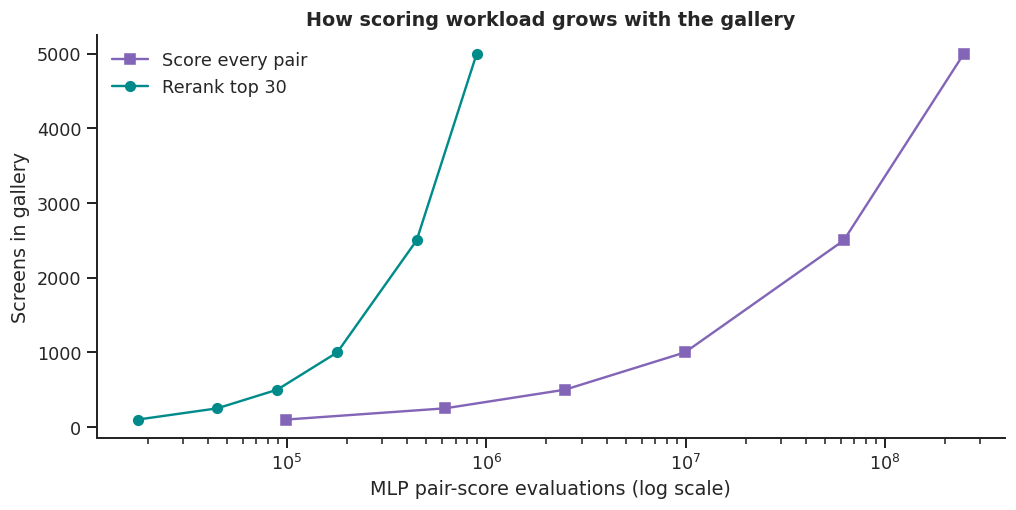

In [22]:
gallery_sizes=np.array([100,250,500,1000,2500,5000])
mean_captions=float(len(cap_table)/len(screens))
full_early_pairs=2*mean_captions*gallery_sizes**2
hybrid_pairs=(1+mean_captions)*gallery_sizes*np.minimum(RETRIEVAL_TOP_K,gallery_sizes)
scale_table=pd.DataFrame({"Screens in gallery":gallery_sizes,
                         "Full early-fusion MLP pair scores":full_early_pairs.astype(int),
                         "Hybrid top-K MLP pair scores":hybrid_pairs.astype(int)})
display(scale_table)
scale_table.to_csv(TAB/"scaling_pair_counts.csv",index=False)
fig,ax=plt.subplots(figsize=(9,4.6))
ax.plot(full_early_pairs,gallery_sizes,marker="s",color="#8365B8",label="Score every pair")
ax.plot(hybrid_pairs,gallery_sizes,marker="o",color="#008B8B",label=f"Rerank top {RETRIEVAL_TOP_K}")
ax.set_xscale("log")
ax.set(xlabel="MLP pair-score evaluations (log scale)",
       ylabel="Screens in gallery",title="How scoring workload grows with the gallery")
ax.legend(frameon=False)
fig.tight_layout();show_plot(fig)

## Final results: fair held-out comparison

In [23]:
@torch.inference_mode()
def sparse_hybrid_latency(model, dual_scores_matrix, gallery, topk=RETRIEVAL_TOP_K):
    """Time the true second-stage MLP forward passes on a shortlist, per direction."""
    model.eval()
    a = torch.from_numpy(gallery["img"]).to(DEVICE)
    b = torch.from_numpy(gallery["txt"]).to(DEVICE)
    k_i = min(topk,len(b))
    k_t = min(topk,len(a))
    start = seconds_now()
    for i in range(0,len(a),64):
        selected_rows = np.arange(i,min(i+64,len(a)))
        ids = np.argpartition(dual_scores_matrix[selected_rows],-k_i,axis=1)[:,-k_i:]
        _ = model(a[torch.tensor(np.repeat(selected_rows,k_i),device=DEVICE)],
                  b[torch.tensor(ids.ravel(),device=DEVICE)])
    for j in range(0,len(b),64):
        selected_cols = np.arange(j,min(j+64,len(b)))
        ids = np.argpartition(dual_scores_matrix[:,selected_cols].T,-k_t,axis=1)[:,-k_t:]
        _ = model(a[torch.tensor(ids.ravel(),device=DEVICE)],
                  b[torch.tensor(np.repeat(selected_cols,k_t),device=DEVICE)])
    return seconds_now()-start

# Run test evaluations once
combined_start = seconds_now()
dual_test,dual_test_s = dual_scores(dual_model,TEST)
early_test,early_test_s = score_early_gallery(early_model,TEST)
hybrid_start = seconds_now()
hybrid_test,hybrid_i2t,hybrid_t2i = hybrid_pair(
    dual_test,early_test,TEST["pos"],alpha=BEST_ALPHA)
hybrid_rerank_s = seconds_now()-hybrid_start
hybrid_sparse_s = sparse_hybrid_latency(early_model,dual_test,TEST)

results = {
    "Random": evaluate_scores(random_test,TEST["pos"]),
    "Ridge": evaluate_scores(ridge_test,TEST["pos"]),
    "Early fusion": evaluate_scores(early_test,TEST["pos"]),
    "Contrastive": evaluate_scores(dual_test,TEST["pos"]),
    "Hybrid reranker": hybrid_test,
}
test_seconds = {"Random":0.0,"Ridge":ridge_test_s,"Early fusion":early_test_s,
                "Contrastive":dual_test_s,"Hybrid reranker":dual_test_s+hybrid_rerank_s+hybrid_sparse_s}
summary = pd.DataFrame([record_metrics(name,result,test_seconds[name])
                        for name,result in results.items()])
display(summary.round(3))
summary.round(6).to_csv(TAB/"08_FINAL_TEST_RESULTS.csv",index=False)
print("Timing excludes pretrained image/text encoders; hybrid includes top-K MLP scoring and ranking.")
print("Hybrid timing measures sparse shortlist MLP scoring in both directions.")
print("Reported timing excludes network transfers, tokenization and image encoding.")

for direction in ["Screen→Text","Text→Screen"]:
    target_delta = results[CHOSEN_METHOD][direction]["R@10"]-results["Ridge"][direction]["R@10"]
    print(f"{CHOSEN_METHOD} vs Ridge, {direction}: {target_delta:+.2f} percentage points",
          "| target met" if target_delta>=5 else "| target not met")

Pairwise fusion scoring:   0%|          | 0/30 [00:00<?, ?it/s]

,Method,Screen→Text R@1,Screen→Text R@5,Screen→Text R@10,Screen→Text MRR,Screen→Text MedR,Text→Screen R@1,Text→Screen R@5,Text→Screen R@10,Text→Screen MRR,Text→Screen MedR,Average R@10,Ranking seconds
0,Random,0.570,1.140,2.564,0.017,220.0,0.174,1.391,2.609,0.017,174.0,2.586,0.000
1,Ridge,1.994,10.826,20.513,0.083,54.0,2.029,10.435,17.507,0.078,51.0,19.010,0.008
2,Early fusion,1.709,7.977,12.536,0.059,77.0,0.986,6.841,11.014,0.051,73.0,11.775,0.157
3,Contrastive,3.419,10.826,21.083,0.094,41.0,2.667,11.304,21.101,0.085,46.0,21.092,0.004
4,Hybrid reranker,2.849,12.536,22.222,0.097,41.0,2.493,12.522,20.580,0.088,46.0,21.401,0.301


Timing excludes pretrained image/text encoders; hybrid includes top-K MLP scoring and ranking.
Hybrid timing measures sparse shortlist MLP scoring in both directions.
Reported timing excludes network transfers, tokenization and image encoding.
Hybrid reranker vs Ridge, Screen→Text: +1.71 percentage points | target not met
Hybrid reranker vs Ridge, Text→Screen: +3.07 percentage points | target not met


### Strict matches versus repeated-description matches

In [24]:
scores_by_method = {
    "Random":random_test,"Ridge":ridge_test,"Early fusion":early_test,
    "Contrastive":dual_test
}
relaxed_rows = []
for method, score_matrix in scores_by_method.items():
    outcome = evaluate_scores(score_matrix, TEST["pos_relaxed"])
    relaxed_rows.append({"Method":method,
                         "Screen→Text R@10 relaxed (%)":outcome["Screen→Text"]["R@10"],
                         "Text→Screen R@10 relaxed (%)":outcome["Text→Screen"]["R@10"]})
hybrid_relaxed = evaluate_scores(hybrid_i2t, TEST["pos_relaxed"],hybrid_t2i)
relaxed_rows.append({"Method":"Hybrid reranker",
                     "Screen→Text R@10 relaxed (%)":hybrid_relaxed["Screen→Text"]["R@10"],
                     "Text→Screen R@10 relaxed (%)":hybrid_relaxed["Text→Screen"]["R@10"]})
relaxed_table = pd.DataFrame(relaxed_rows)
display(relaxed_table.round(2))
relaxed_table.to_csv(TAB/"08b_RELAXED_TEST_RESULTS.csv",index=False)
print("The strict table remains the primary comparison; do not choose models from this test table.")

,Method,Screen→Text R@10 relaxed (%),Text→Screen R@10 relaxed (%)
0,Random,2.85,3.25
1,Ridge,20.80,20.41
2,Early fusion,13.11,13.33
3,Contrastive,21.65,24.29
4,Hybrid reranker,23.08,23.77


The strict table remains the primary comparison; do not choose models from this test table.


### Final recall by model and search direction

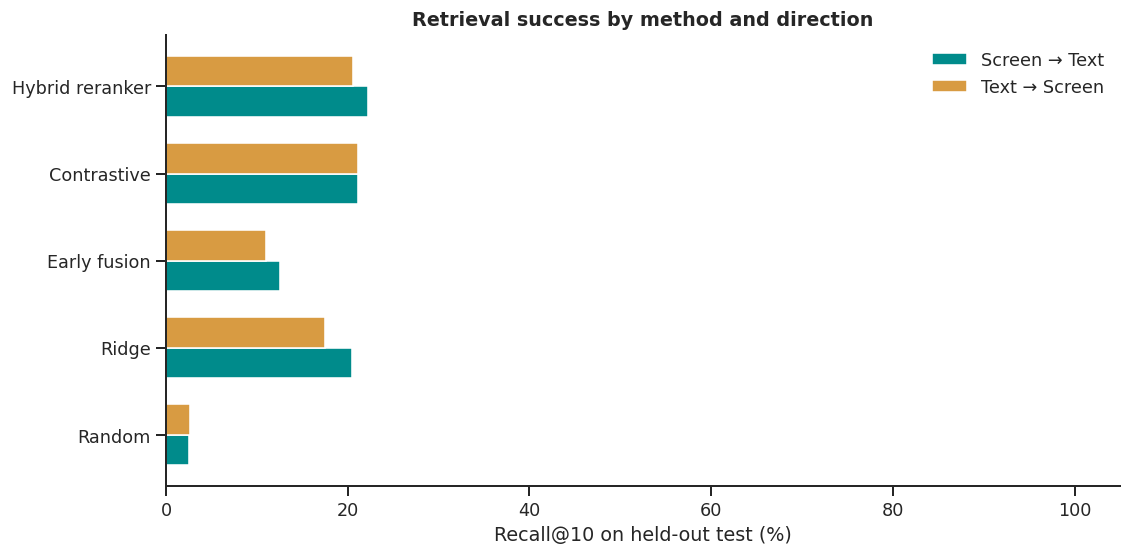

In [25]:
methods=list(results)
y=np.arange(len(methods));width=.35
left=[results[m]["Screen→Text"]["R@10"] for m in methods]
right=[results[m]["Text→Screen"]["R@10"] for m in methods]
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(y-width/2,left,height=width,color="#008B8B",label="Screen → Text")
ax.barh(y+width/2,right,height=width,color="#D89B42",label="Text → Screen")
ax.set_yticks(y,methods)
ax.set(xlabel="Recall@10 on held-out test (%)",xlim=(0,105),
       title="Retrieval success by method and direction")
ax.legend(frameon=False)
fig.tight_layout();show_plot(fig)

## Visual comparison: retrieval performance, efficiency and model stability

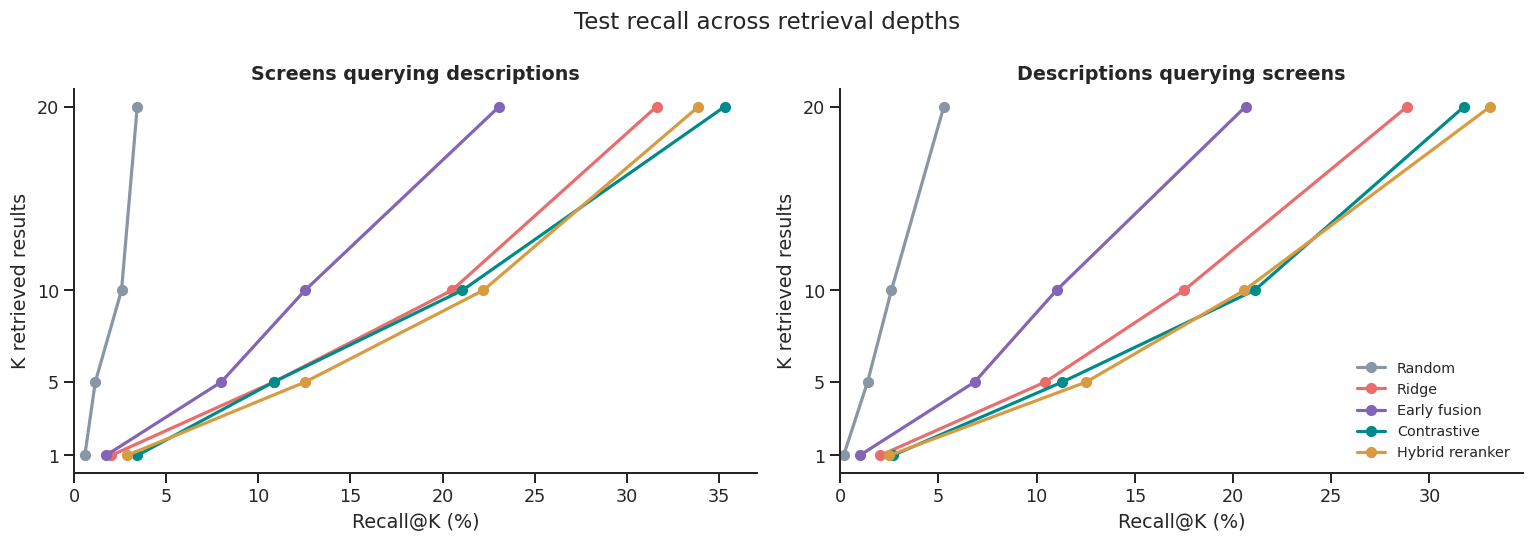

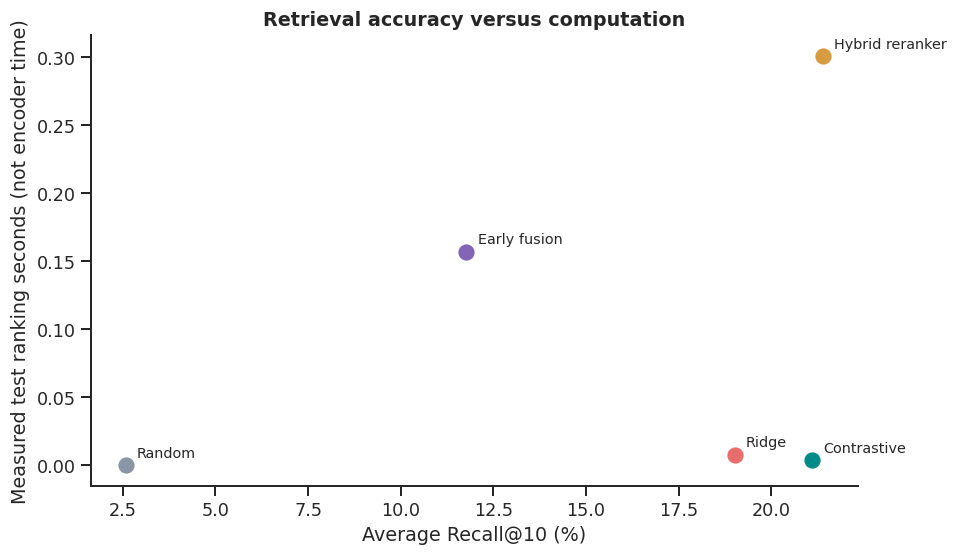

,seed,best_val_R10,best_epoch,training_seconds
0,42,24.749972,19,10.157805
1,123,24.685588,6,4.645709
2,456,25.287226,10,7.572728


Validation R@10 standard deviation across seeds: 0.27


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13.5,4.8))
for ax,(key,label) in zip(axes,[("Screen→Text","Screens querying descriptions"),
                                ("Text→Screen","Descriptions querying screens")]):
    rank_key = "rank_i2t" if key=="Screen→Text" else "rank_t2i"
    for method,result in results.items():
        y = [np.mean(result[rank_key]<=k)*100 for k in [1,5,10,20]]
        ax.plot(y,[1,5,10,20],marker="o",lw=2,label=method,color=COLORS[method])
    ax.set(xlabel="Recall@K (%)",ylabel="K retrieved results",title=label)
    ax.set_yticks([1,5,10,20]);ax.set_xlim(left=0)
axes[1].legend(frameon=False,fontsize=9,loc="best")
fig.suptitle("Test recall across retrieval depths")
fig.tight_layout();show_plot(fig)

fig,ax=plt.subplots(figsize=(8.5,5))
for method in summary.Method:
    row = summary.set_index("Method").loc[method]
    ax.scatter(row["Average R@10"],row["Ranking seconds"],s=125,
               color=COLORS[method],edgecolor="white",zorder=3)
    ax.annotate(method,(row["Average R@10"],row["Ranking seconds"]),
                xytext=(7,5),textcoords="offset points",fontsize=9)
ax.set(ylabel="Measured test ranking seconds (not encoder time)",
       xlabel="Average Recall@10 (%)",title="Retrieval accuracy versus computation")
fig.tight_layout();show_plot(fig)

# Stability is reported for validation
seed_stability = pd.DataFrame([{"seed":r["seed"],"best_val_R10":r["val_audit_R10"],
                                "best_epoch":r["best_epoch"],"training_seconds":r["seconds"]}
                               for r in dual_runs])
display(seed_stability)
seed_stability.to_csv(TAB/"09_seed_stability.csv",index=False)
print("Validation R@10 standard deviation across seeds:",round(seed_stability.best_val_R10.std(ddof=0),2))

## Subgroup evaluation, confidence intervals and limitations


Subgroup model selected on validation: Hybrid reranker


,Screens,Screen_to_text_R10,Text_to_screen_R10
category,,,
Health & Fitness,10,0.00,10.00
Parenting,16,25.00,11.56
Education,25,12.00,12.80
Shopping,27,14.81,14.57
Business,19,21.05,14.74
Music & Audio,17,17.65,15.29
News & Magazines,12,16.67,20.00
Books & Reference,17,11.76,20.88
Finance,22,18.18,21.14


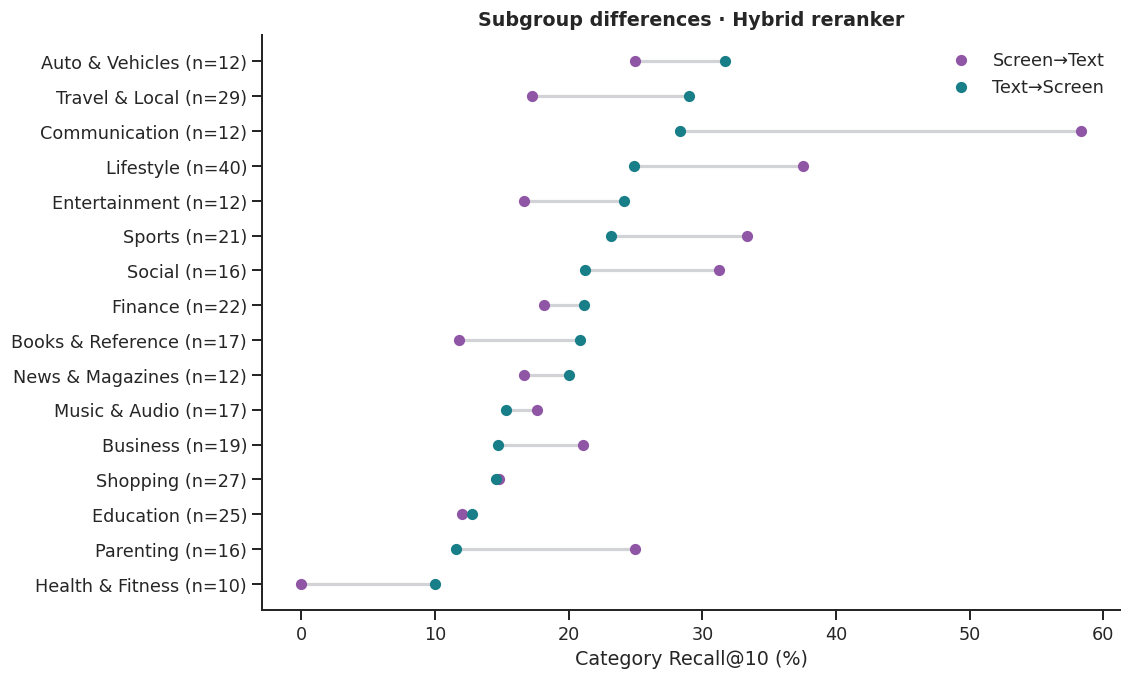

,direction,observed_pp,CI_low_pp,CI_high_pp
0,Screen→Text,1.71,-2.56,6.55
1,Text→Screen,3.12,0.81,5.46


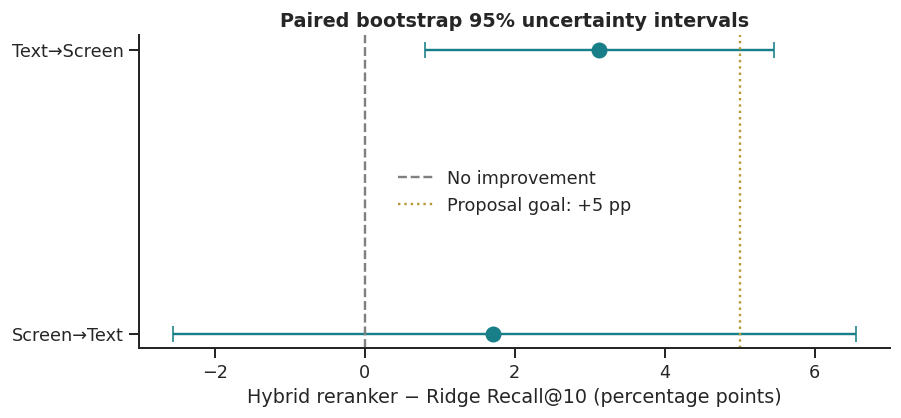

In [27]:
# Per-caption hits are rolled up to image groups for fair category reporting.
def t2i_mean_hit_per_screen(result, gallery, k=10):
    cap_to_local_img = {int(img_id):p for p,img_id in enumerate(gallery["img_ids"])}
    holder = defaultdict(list)
    for t,global_img in enumerate(gallery["caption_img"]):
        holder[cap_to_local_img[int(global_img)]].append(float(result["rank_t2i"][t] <= k))
    return np.asarray([np.mean(holder[i]) for i in range(len(gallery["img_ids"]))])

best_method = CHOSEN_METHOD  # selected using validation
cat_eval = pd.DataFrame({"category":TEST["categories"],
                         "screen_hits":results[best_method]["rank_i2t"]<=10,
                         "caption_hits":t2i_mean_hit_per_screen(results[best_method],TEST)})
cat_summary = cat_eval.groupby("category").agg(
    Screens=("screen_hits","size"),
    Screen_to_text_R10=("screen_hits","mean"),
    Text_to_screen_R10=("caption_hits","mean"))
cat_summary[["Screen_to_text_R10","Text_to_screen_R10"]] *= 100
cat_summary = cat_summary[cat_summary.Screens>=10].sort_values("Text_to_screen_R10")
cat_summary.round(2).to_csv(TAB/"10_category_comparison.csv")
print("Subgroup model selected on validation:",best_method)
display(cat_summary.round(2))

if len(cat_summary):
    fig,ax=plt.subplots(figsize=(10,max(4,len(cat_summary)*.38)))
    y=np.arange(len(cat_summary))
    ax.plot(np.vstack([cat_summary.Screen_to_text_R10,cat_summary.Text_to_screen_R10]),
            np.vstack([y,y]),color="#D1D3D7",lw=2)
    ax.scatter(cat_summary.Screen_to_text_R10,y,color="#8F56A6",label="Screen→Text",zorder=3)
    ax.scatter(cat_summary.Text_to_screen_R10,y,color="#187E87",label="Text→Screen",zorder=3)
    ax.set_yticks(y,[f"{name} (n={int(n)})" for name,n in zip(cat_summary.index,cat_summary.Screens)])
    ax.set(xlabel="Category Recall@10 (%)",title=f"Subgroup differences · {best_method}")
    ax.legend(frameon=False)
    fig.tight_layout();show_plot(fig)

#bootstrap on screens, not independently on correlated captions
def bootstrap_difference(learned, baseline, gallery, direction, repeats=1000,seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(gallery["img_ids"])
    if direction == "Screen→Text":
        a = (learned["rank_i2t"]<=10).astype(float)
        b = (baseline["rank_i2t"]<=10).astype(float)
    else:
        a = t2i_mean_hit_per_screen(learned,gallery)
        b = t2i_mean_hit_per_screen(baseline,gallery)
    diffs = np.asarray([(a[ids]-b[ids]).mean()*100
                        for ids in rng.integers(0,n,size=(repeats,n))])
    return {"direction":direction,"observed_pp":float((a-b).mean()*100),
            "CI_low_pp":float(np.percentile(diffs,2.5)),
            "CI_high_pp":float(np.percentile(diffs,97.5))}

confidence = pd.DataFrame([bootstrap_difference(results[CHOSEN_METHOD],results["Ridge"],TEST,d)
                           for d in ["Screen→Text","Text→Screen"]])
display(confidence.round(2))
confidence.to_csv(TAB/"11_bootstrap_improvement.csv",index=False)

fig,ax=plt.subplots(figsize=(8,3.8))
y=np.arange(len(confidence))
ax.errorbar(confidence.observed_pp,y,xerr=[confidence.observed_pp-confidence.CI_low_pp,
                                           confidence.CI_high_pp-confidence.observed_pp],
            fmt="o",capsize=5,color="#187E87",markersize=9)
ax.axvline(0,c="grey",ls="--",label="No improvement")
ax.axvline(5,c="#B59A3B",ls=":",label="Proposal goal: +5 pp")
ax.set_yticks(y,confidence.direction)
ax.set(xlabel=f"{CHOSEN_METHOD} − Ridge Recall@10 (percentage points)",
       title="Paired bootstrap 95% uncertainty intervals")
ax.legend(frameon=False);fig.tight_layout();show_plot(fig)

## Retrieval examples to see the screenshots and the predictions

,Description,Correct-image rank,Top retrieved categories
0,screen displaying home page of an e-wallet app...,350,Parenting / Entertainment / Travel & Local
1,page showing information about various places,344,Travel & Local / Travel & Local / News & Magaz...
2,page displaying an option to change language,342,Travel & Local / News & Magazines / Travel & L...
3,page showing the reviews of hotels,342,Education / Finance / Travel & Local
4,page displaying the search bar result,341,Shopping / Entertainment / Lifestyle
5,permission page of a media player app,339,Maps & Navigation / Books & Reference / Commun...
6,search bar page in a english dictionary app,339,Parenting / House & Home / Lifestyle
7,screen displaying about weather alert,337,Travel & Local / Music & Audio / Weather


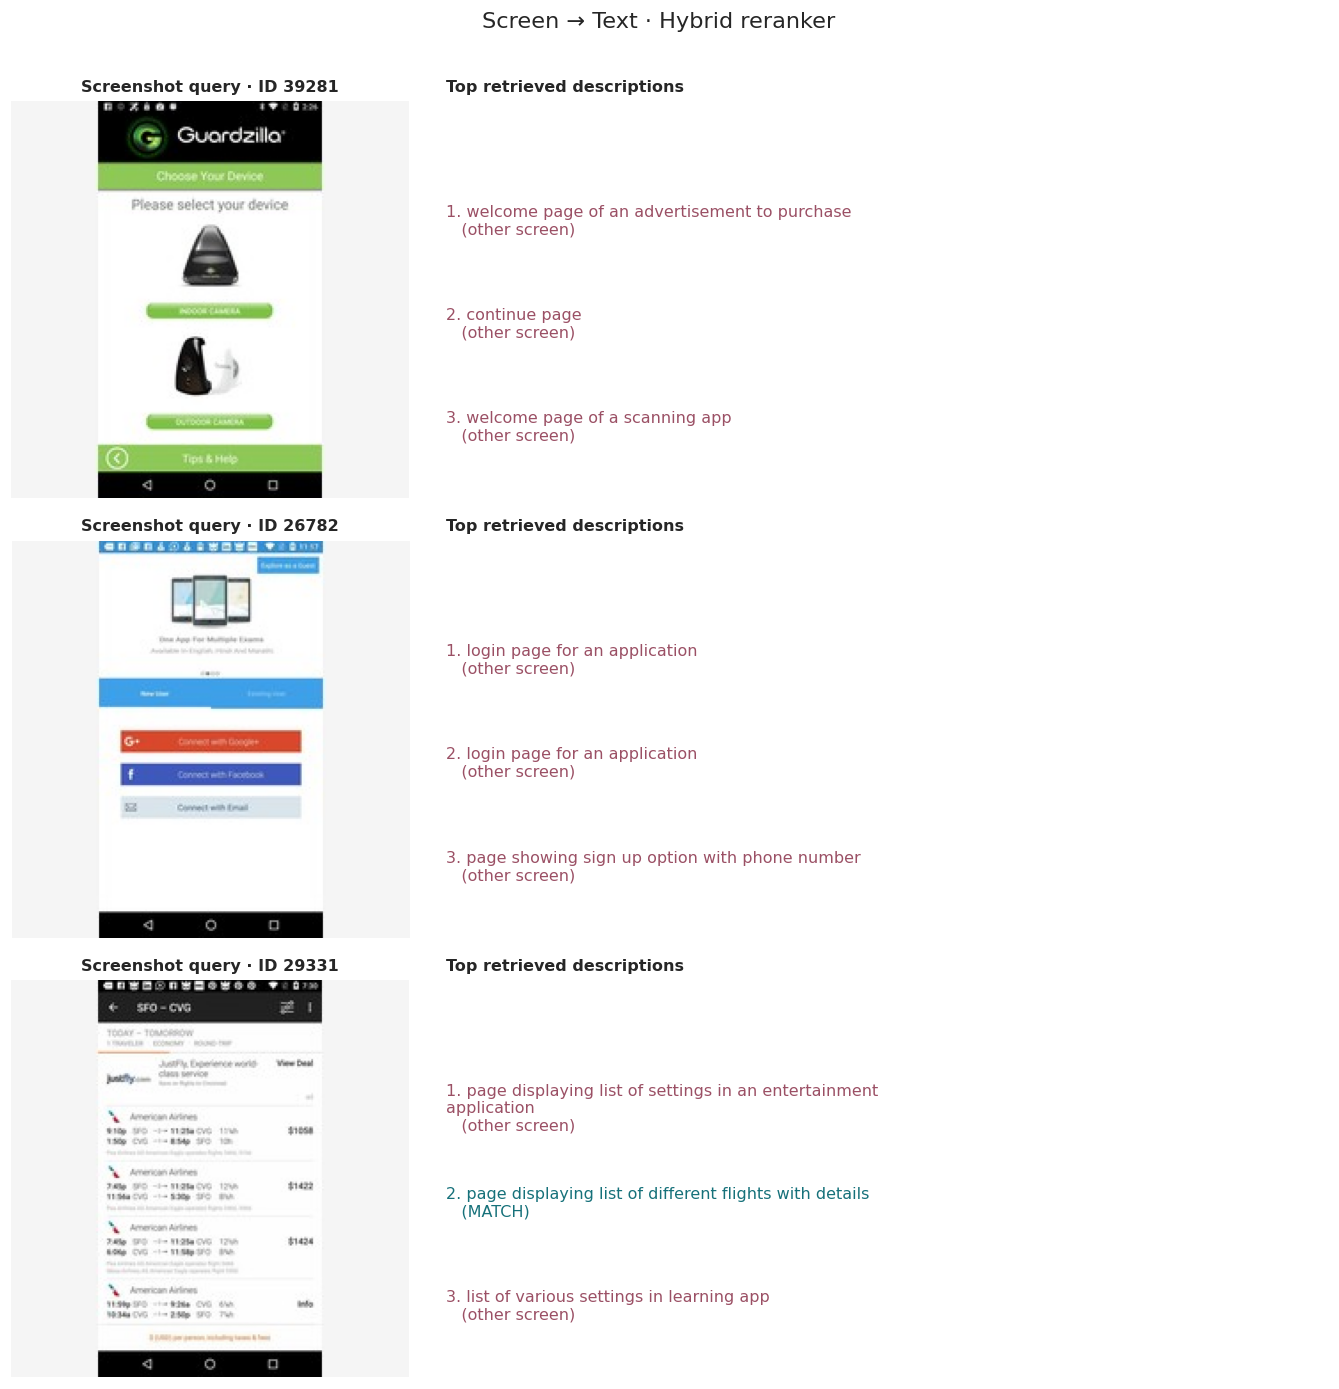

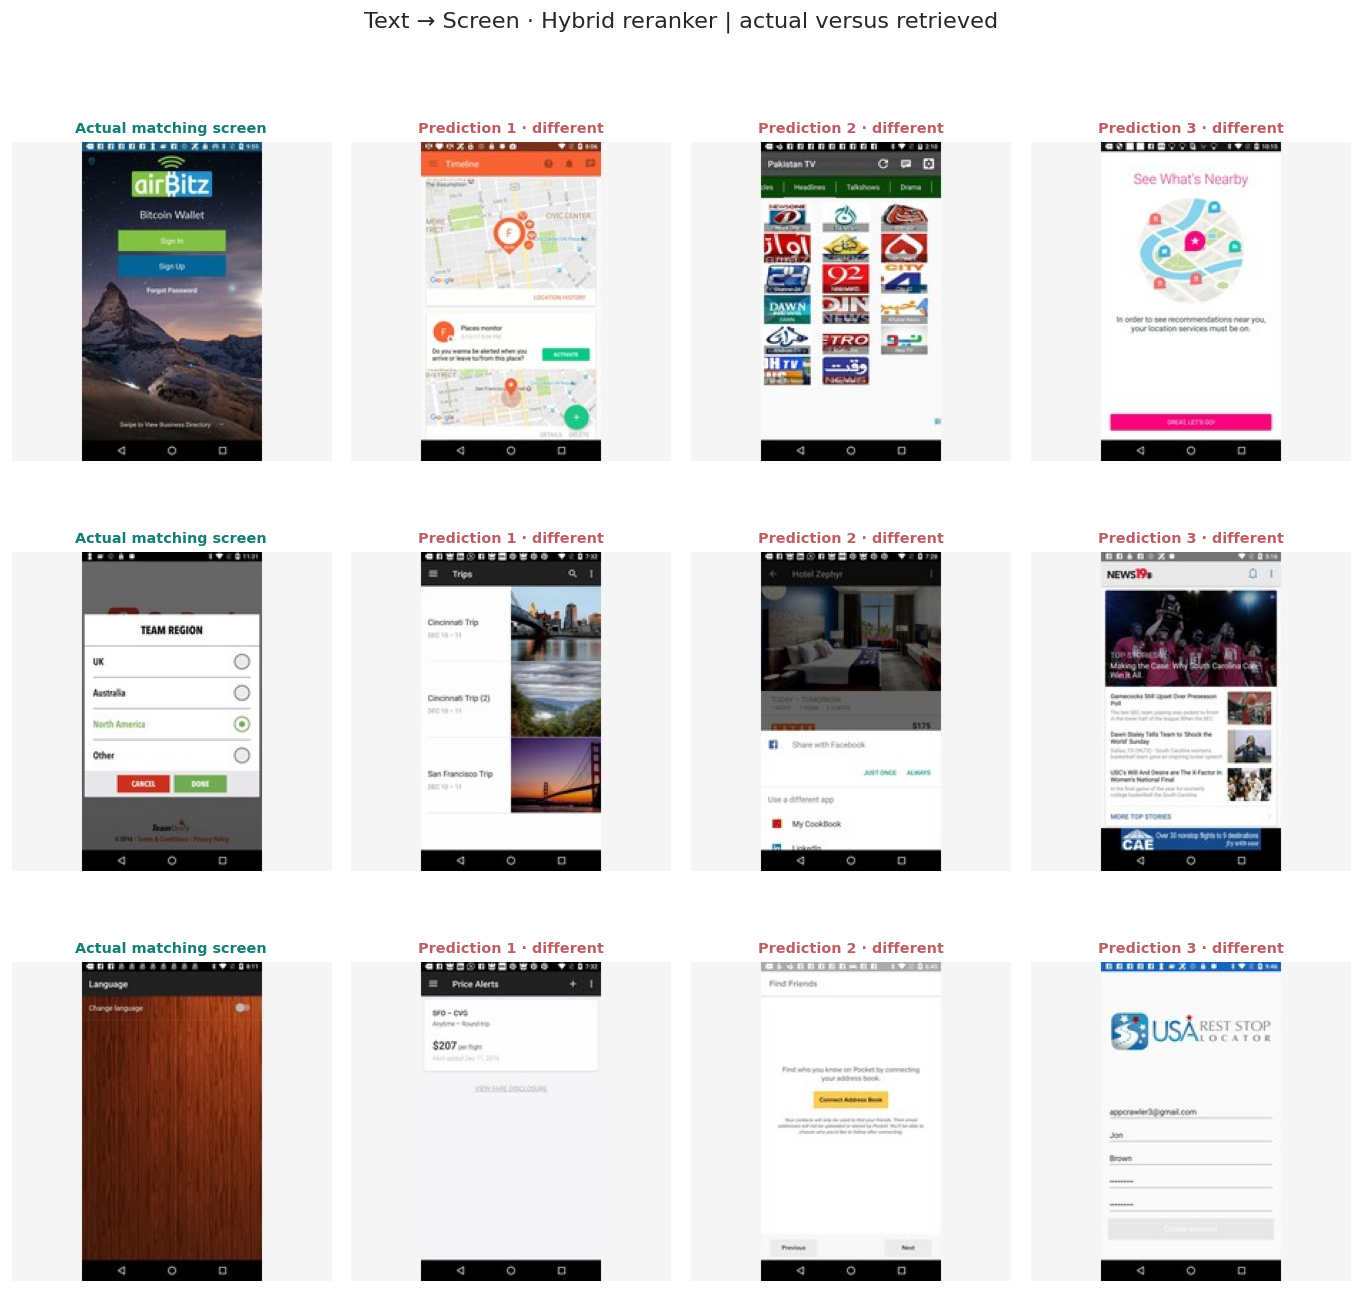

Privacy reminder: the screenshot panels above are for private inspection, not publication without checking.


In [28]:
# We chose the method using VALIDATION earlier
if CHOSEN_METHOD == "Early fusion":
    chosen_i2t = early_test
    chosen_t2i = early_test.T
elif CHOSEN_METHOD == "Hybrid reranker":
    chosen_i2t = hybrid_i2t
    chosen_t2i = hybrid_t2i
else:
    chosen_i2t = dual_test
    chosen_t2i = dual_test.T

rank_values = results[CHOSEN_METHOD]["rank_t2i"]
hard_queries = np.argsort(-rank_values)[:8]
error_records = []
for q in hard_queries:
    candidates = np.argsort(-chosen_t2i[q])[:3]
    query = cap_table.caption.iloc[TEST["cap_ids"][q]]
    if PERSONAL_TEXT_RE.search(query):
        query = "[POTENTIALLY PRIVATE TEXT REDACTED]"
    error_records.append({
        "Description": query,
        "Correct-image rank": int(rank_values[q]),
        "Top retrieved categories": " / ".join(TEST["categories"][candidates])
    })
error_table = pd.DataFrame(error_records)
display(error_table)
error_table.to_csv(TAB / "retrieval_failure_examples.csv", index=False)

reviewed_ids = set(review_screen_ids) - set(FLAGGED_SCREEN_IDS)
reviewed_test_positions = [
    i for i, image_index in enumerate(TEST["img_ids"])
    if int(screens.screenId.iloc[int(image_index)]) in reviewed_ids
]
example_rng = np.random.default_rng(SEED + 200)
if reviewed_test_positions:
    example_imgs = np.asarray(reviewed_test_positions[:min(3, len(reviewed_test_positions))])
else:
    example_imgs = example_rng.choice(len(TEST["img_ids"]),
                                     min(3, len(TEST["img_ids"])), replace=False)

fig, axes = plt.subplots(len(example_imgs), 2,
                         figsize=(12, max(4, len(example_imgs) * 4)),
                         gridspec_kw={"width_ratios": [1, 2]}, squeeze=False)
for row_num, position in enumerate(example_imgs):
    image_index = int(TEST["img_ids"][position])
    img_record = screens.iloc[image_index]
    with Image.open(img_record.image_path) as picture:
        axes[row_num, 0].imshow(picture)
    axes[row_num, 0].set_title(f"Screenshot query · ID {int(img_record.screenId)}", fontsize=10)
    axes[row_num, 0].axis("off")
    picked = np.argsort(-chosen_i2t[position])[:3]
    descriptions = [cap_table.caption.iloc[int(TEST["cap_ids"][j])] for j in picked]
    axes[row_num, 1].axis("off")
    axes[row_num, 1].set_title("Top retrieved descriptions", loc="left", fontsize=10)
    for k, (cap_local, description) in enumerate(zip(picked, descriptions), start=1):
        belongs = int(TEST["caption_img"][cap_local]) == image_index
        note = "MATCH" if belongs else "other screen"
        text_value = re.sub(r"\s+", " ", description)
        if PERSONAL_TEXT_RE.search(text_value):
            text_value = "[Potential identifying text withheld]"
        axes[row_num, 1].text(0.0, 1 - k * 0.26,
            f"{k}. {textwrap.fill(text_value, 60)}\n   ({note})",
            va="top", fontsize=10, transform=axes[row_num, 1].transAxes,
            color="#16717A" if belongs else "#9B5065")
fig.suptitle(f"Screen → Text · {CHOSEN_METHOD}", y=1.005, fontsize=14)
fig.tight_layout()
show_plot(fig)

example_queries = hard_queries[:min(3, len(hard_queries))]
fig, axes = plt.subplots(len(example_queries), 4,
                         figsize=(12, max(4.0, 3.9 * len(example_queries))), squeeze=False)
for row_num, q in enumerate(example_queries):
    text = cap_table.caption.iloc[int(TEST["cap_ids"][q])]
    owning_idx = int(TEST["caption_img"][q])
    owning_row = screens.iloc[owning_idx]
    retrieved = np.argsort(-chosen_t2i[q])[:3]
    to_show = [owning_idx] + [int(TEST["img_ids"][p]) for p in retrieved]
    for col_num, original_screen_idx in enumerate(to_show):
        item = screens.iloc[original_screen_idx]
        with Image.open(item.image_path) as picture:
            axes[row_num, col_num].imshow(picture)
        if col_num == 0:
            title = "Actual matching screen"
        else:
            correct = original_screen_idx == owning_idx
            title = f"Prediction {col_num} · {'match' if correct else 'different'}"
        axes[row_num, col_num].set_title(title, fontsize=9,
                                         color="#137C75" if original_screen_idx == owning_idx else "#BC5F65")
        axes[row_num, col_num].axis("off")
    if PERSONAL_TEXT_RE.search(text):
        text = "[Identifying query withheld]"
    axes[row_num, 0].set_ylabel(textwrap.fill(text, 26), fontsize=9)
fig.suptitle(f"Text → Screen · {CHOSEN_METHOD} | actual versus retrieved", y=1.005, fontsize=14)
fig.tight_layout()
show_plot(fig)
print("Privacy reminder: the screenshot panels above are for private inspection, not publication without checking.")


## Interpret results, overfitting, scalability and ethics

In [29]:
# Parameter counts and summary for technical audience.
parameters = pd.DataFrame([
  {"Method":"Ridge", "Trainable parameters":int(ridge.coef_.size+ridge.intercept_.size),
   "Training seconds":ridge_training_s},
  {"Method":"Early fusion","Trainable parameters":sum(p.numel() for p in early_model.parameters()),
   "Training seconds":early_training_s},
  {"Method":"Contrastive","Trainable parameters":sum(p.numel() for p in dual_model.parameters()),
   "Training seconds":selected_run["seconds"]},
])
display(parameters)
parameters.to_csv(TAB/"13_complexity.csv",index=False)

stability_gap = (selected_run["history"].iloc[selected_run["best_epoch"]-1].train_R10 -
                 selected_run["history"].iloc[selected_run["best_epoch"]-1].val_R10)
print(f"Overfitting audit at chosen epoch: train–validation Average R@10 = {stability_gap:+.2f} pp")
print("TEST comparison:")
display(summary[["Method","Screen→Text R@10","Text→Screen R@10","Average R@10","Ranking seconds"]].round(2))

best_on_test = summary.sort_values("Average R@10",ascending=False).iloc[0]
print(f"Descriptive highest test Avg Recall@10: {best_on_test.Method} ({best_on_test['Average R@10']:.1f}%).")
print("Do NOT use this test ranking to retroactively tune models. Explain method choice using validation & cost.")

,Method,Trainable parameters,Training seconds
0,Ridge,16512,0.120359
1,Early fusion,89857,7.516158
2,Contrastive,115393,7.572728


Overfitting audit at chosen epoch: train–validation Average R@10 = +52.35 pp
TEST comparison:


,Method,Screen→Text R@10,Text→Screen R@10,Average R@10,Ranking seconds
0,Random,2.56,2.61,2.59,0.00
1,Ridge,20.51,17.51,19.01,0.01
2,Early fusion,12.54,11.01,11.78,0.16
3,Contrastive,21.08,21.10,21.09,0.00
4,Hybrid reranker,22.22,20.58,21.40,0.30


Descriptive highest test Avg Recall@10: Hybrid reranker (21.4%).
Do NOT use this test ranking to retroactively tune models. Explain method choice using validation & cost.
